# BENCHMARK CÁC THUẬT TOÁN MACHINE LEARNING TRONG PHÂN LOẠI BÌNH LUẬN TOXIC / NON-TOXIC VỀ PHIM "MƯA ĐỎ" TRÊN FACEBOOK

**Phiên bản viết lại – chạy end-to-end, không hardcode số liệu.** Mọi con số trong bảng, biểu đồ và phần Kết luận đều được tính trực tiếp từ dữ liệu trong notebook này. Chạy **Restart & Run All** là tái lập toàn bộ kết quả.

## Tổng quan

* **Bài toán:** phân loại nhị phân bình luận tiếng Việt: Toxic (1) và Non-toxic (0).
* **Dữ liệu:** file `mua_do_comments_labeled_final.csv` (3 cột: `id_comment`, `comment`, `label`), nhãn do LLM gán.
* **Phương pháp:** ML truyền thống (BoW / TF-IDF + MNB, CNB, LR, LinearSVC, SGD), chuẩn hóa ngôn ngữ mạng xã hội, dò ngưỡng trên Out-Of-Fold (OOF).
* **Metric chính:** Toxic F1 và PR-AUC (lớp thiểu số), kèm Macro F1. Accuracy chỉ để tham khảo vì lớp Toxic rất hiếm.

## Những điểm đã sửa so với bản cũ

| Vấn đề ở bản cũ | Cách xử lý ở bản này |
| :--- | :--- |
| Notebook chỉ đọc CSV/PNG có sẵn, không chứa CV, tuning, dò ngưỡng, huấn luyện | Toàn bộ pipeline thực nghiệm nằm trong notebook |
| Nhiều số in cứng (ổn định, ngưỡng, "Recall 52% → 75%", kết luận) | Tất cả tính động; Kết luận được sinh từ biến kết quả |
| Dev–Test trùng nội dung (67 mẫu) nhưng vẫn tuyên bố "zero leakage" | Khử trùng lặp **trước khi chia**, `assert` giao thoa bằng 0, thêm kiểm tra near-duplicate |
| So sánh PR-AUC lẫn CV với Test | Mọi so sánh giữa các mô hình dùng cùng bộ fold CV |
| Ablation không có kiểm định | Kiểm định t có hiệu chỉnh Nadeau–Bengio trên 15 lượt CV |
| Thiếu import, tham số `index_index` sai, nhãn phiên bản sai | Đã sửa, in đúng phiên bản thư viện |
| "Chẩn đoán" lỗi là một câu chung cho mọi ca | Giải thích từng ca bằng các n-gram đóng góp lớn nhất |
| Không có CI cho F1 / PR-AUC, Test chỉ ~128 mẫu Toxic | Bootstrap 95% CI + Wilson CI |
| Nhãn LLM chưa được kiểm định | Xuất `label_audit_sample.csv` để kiểm tra thủ công |

## Mục lục

1. Môi trường và cấu hình
2. Data loading và data understanding
3. Cleaning và preprocessing (khử trùng lặp trước khi chia)
4. Data splitting và experiment design
5. Baseline experiments
6. Model optimization (ablation tiền xử lý, tuning, BoW vs TF-IDF)
7. Robustness and stability analysis
8. Threshold optimization
9. Final model evaluation
10. Error analysis và model interpretation
11. Conclusion

## PHẦN 1. MÔI TRƯỜNG VÀ CẤU HÌNH

Cố định `RANDOM_STATE = 42`, tạo thư mục kết quả, tự tìm file dữ liệu và in đúng phiên bản các thư viện.

In [1]:
import sys; sys.path.append(str(__import__('pathlib').Path.cwd() / '.runtime'))
import os, sys, time, json, math, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, scipy, sklearn
from scipy import stats
from joblib import Parallel, delayed
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, balanced_accuracy_score,
    matthews_corrcoef, confusion_matrix, classification_report,
    precision_recall_curve,
)

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

# ---- Cấu hình thực nghiệm -----------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
TEST_SIZE = 0.20
N_SPLITS = 5          # số fold
N_REPEATS = 3         # số lần lặp cho Repeated Stratified K-Fold (3 x 5 = 15 lượt)
N_JOBS = -1           # số tiến trình song song (-1 = tất cả CPU)
N_BOOT = 1000         # số lần bootstrap cho CI trên Test
NEAR_DUP_COS = 0.90   # ngưỡng cosine coi là near-duplicate

# ---- Đường dẫn ----------------------------------------------------------------
ROOT = Path.cwd()
BENCHMARK_DIR = ROOT if ROOT.name == 'BENCHMARK_TOXIC' else ROOT / 'BENCHMARK_TOXIC'
DATA_DIR, RESULTS_DIR = BENCHMARK_DIR / 'data', BENCHMARK_DIR / 'results'
FIGURES_DIR, MODELS_DIR = BENCHMARK_DIR / 'figures', BENCHMARK_DIR / 'models'
for d in (DATA_DIR, RESULTS_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

DATA_NAME = 'mua_do_comments_labeled_final.csv'
candidates = [ROOT / DATA_NAME, ROOT.parent / DATA_NAME, BENCHMARK_DIR / DATA_NAME,
              DATA_DIR / DATA_NAME, DATA_DIR / 'raw_comments.csv']
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy dữ liệu. Đã thử:\n' + '\n'.join(map(str, candidates)))

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / name, dpi=150, bbox_inches='tight')
    from IPython.display import Image as NotebookImage
    plt.close()
    display(NotebookImage(filename=str(FIGURES_DIR / name)))

print(f'Dữ liệu:       {DATA_PATH}')
print(f'Thư mục kết quả: {BENCHMARK_DIR}')
print(f'Random state:  {RANDOM_STATE}')
print(f'Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scikit-learn {sklearn.__version__} | scipy {scipy.__version__}')

mkdir -p failed for path C:\Users\Administrator\AppData\Local\matplotlib: [WinError 5] Access is denied: 'C:\\Users\\Administrator\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\ADMINI~1\AppData\Local\Temp\matplotlib-vcclhkly because there was an issue with the default path (C:\Users\Administrator\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Dữ liệu:       D:\file moi btl;\mua_do_comments_labeled_final.csv
Thư mục kết quả: D:\file moi btl;\BENCHMARK_TOXIC
Random state:  42
Python 3.12.10 | numpy 2.5.2 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1


### Module tiền xử lý `toxic_preprocess.py`

Hàm tiền xử lý được ghi ra một file module riêng. Lý do: khi lưu mô hình bằng `joblib`, hàm nằm trong notebook (`__main__`) rất khó nạp lại ở nơi khác; còn module thì import được ở bất kỳ đâu. Các bước thay đổi so với bản cũ:

* Bỏ ánh xạ các từ đơn quá mơ hồ (`t → tao`, `m → mày`) và `xl → xin lỗi` (trùng nghĩa với size XL).
* Dấu phân cách trong các chuỗi ngụy trang (`d.c.m`, `v.c.l`…) không còn cho phép khoảng trắng trần, tránh khớp nhầm.
* Thêm emoji cười (`😂`, `🤣`) vào nhóm tiếng cười và bỏ ký tự biến thể emoji `U+FE0F`.

In [2]:
PREPROCESS_FILE = BENCHMARK_DIR / 'toxic_preprocess.py'
PREPROCESS_SRC = r'''
import html, re, unicodedata

EMOJI_DICT = {
    '🤮': 'icon_nôn_mửa', '🤢': 'icon_buồn_nôn', '💩': 'icon_phân', '🤬': 'icon_chửi_bới',
    '😡': 'icon_tức_giận', '😠': 'icon_giận_dữ', '👿': 'icon_ác_quỷ', '🖕': 'icon_ngón_tay_thối',
    '👎': 'icon_chê_bai', '🤡': 'icon_hề_hước', '🐶': 'icon_chó', '🐕': 'icon_chó',
    '🐷': 'icon_lợn', '🐖': 'icon_lợn', '🐂': 'icon_bò', '🐃': 'icon_trâu_bò',
    '🙂': 'icon_mỉa_mai', '🙃': 'icon_châm_chọc', '😏': 'icon_khinh_khỉnh', '😒': 'icon_khó_chịu',
    '🙄': 'icon_đảo_mắt', '🥱': 'icon_nhàm_chán', '😴': 'icon_buồn_ngủ', '🇻🇳': 'icon_cờ_việt_nam',
    '❤': 'icon_yêu_thích', '💖': 'icon_yêu_thích', '💐': 'icon_hoa_tri_ân', '🌸': 'icon_hoa_tri_ân',
    '🕯': 'icon_thắp_nến', '🪦': 'icon_bia_mộ', '🫡': 'icon_chào_kính_cẩn', '🙏': 'icon_cầu_nguyện',
    '😭': 'icon_khóc_xúc_động', '😢': 'icon_khóc_xúc_động', '🥺': 'icon_xúc_động', '🥹': 'icon_xúc_động',
    '🔥': 'icon_bùng_nổ', '👍': 'icon_thích', '😂': 'icon_cười_lớn', '🤣': 'icon_cười_lớn',
}

TEENCODE_DICT = {
    'vc': 'vãi cứt', 'vcl': 'vãi cả lồn', 'vl': 'vãi lồn', 'vcc': 'vãi cả cặc',
    'vlon': 'vãi lồn', 'vkl': 'vãi cả lồn', 'vleu': 'vãi lồn', 'vloz': 'vãi lồn',
    'cl': 'cái lồn', 'clgt': 'cái lồn gì thế', 'cmn': 'con mẹ nó', 'cmnr': 'con mẹ nó rồi',
    'cc': 'con cặc', 'cclgt': 'con cặc gì thế', 'cẹc': 'cặc', 'kẹc': 'cặc',
    'đm': 'địt mẹ', 'dm': 'địt mẹ', 'dcm': 'địt con mẹ', 'đcm': 'địt con mẹ',
    'dmm': 'địt mẹ mày', 'đmm': 'địt mẹ mày', 'đkm': 'địt con mẹ', 'dkm': 'địt con mẹ',
    'cml': 'con mặt lồn', 'sml': 'sấp mặt lồn', 'dell': 'đéo',
    'đếch': 'đéo', 'đíu': 'đéo', 'méo': 'đéo',
    'ngu lol': 'ngu lồn', 'ngu l': 'ngu lồn', 'ngu loz': 'ngu lồn', 'ngu cc': 'ngu con cặc',
    'xàm lol': 'xàm lồn', 'xàm l': 'xàm lồn', '3 que': 'ba que',
    'rác rưởi': 'rác rưởi', 'rác': 'rác rưởi',
    'dẩm dờ': 'dẩm dờ', 'dẩm': 'dẩm dờ', 'xàm xí': 'xàm xí', 'xàm': 'xàm xí',
    'hãm tài': 'hãm tài', 'hãm': 'hãm tài',
    'k': 'không', 'ko': 'không', 'kh': 'không', 'dc': 'được',
    'bt': 'biết', 'bít': 'biết', 'r': 'rồi', 'rùi': 'rồi', 'mn': 'mọi người', 'mng': 'mọi người',
    'z': 'vậy', 'zậy': 'vậy', 'mik': 'mình', 'mk': 'mình',
}

HTML_PATTERN = re.compile(r'<.*?>')
URL_PATTERN = re.compile(r'https?://\S+|www\.\S+')
WHITESPACE_PATTERN = re.compile(r'\s+')
LAUGHTER_PATTERN = re.compile(r'(?i)\b(k{3,}|h{3,}|(ha){2,}|(hi){2,}|(he){2,}|(ho){2,}|a+h+a+|h+a+h+)\b')
SLEEP_PATTERN = re.compile(r'(?i)\b(z{3,})\b')

# Chuỗi viết tắt thô tục bị ngụy trang bằng dấu chấm/gạch (d.c.m, v.c.l, c.l.g.t ...).
# Dấu phân cách bắt buộc có ít nhất một ký tự . - _ / * (khoảng trắng chỉ được đi kèm).
_SEP = r'\s*[\.\-_/\*]+\s*'
def _obf(letters):
    return re.compile(r'(?i)\b' + _SEP.join(letters) + r'\b')

OBFUSCATION_RULES = [
    (_obf(['c', 'l', 'g', 't']), ' cái_lồn_gì_thế '),
    (_obf(['[đd]', 'c', 'm', 'm']), ' địt_con_mẹ_mày '),
    (_obf(['[đd]', 'c', 'm']), ' địt_con_mẹ '),
    (_obf(['v', 'c', 'l']), ' vãi_cả_lồn '),
    (_obf(['v', 'c', '[đd]']), ' vãi_cả_đái '),
    (_obf(['[đd]', 'm', 'm']), ' địt_mẹ_mày '),
    (_obf(['c', 'm', 'm']), ' con_mẹ_mày '),
    (_obf(['c', 'm', 'n']), ' con_mẹ_nó '),
    (_obf(['[đd]', 'm']), ' địt_mẹ '),
    (_obf(['c', 'l']), ' cái_lồn '),
]

MISC_RULES = [
    (re.compile(r'(?i)\bc(?:[\.\-_/\*]+ứ[\.\-_/\*]*|ứ[\.\-_/\*]+)t\b'), 'cứt'),
    (re.compile(r'(?i)\bđ\s+ịt\b'), 'địt'),
    (re.compile(r'(?i)\bl\s+ồn\b'), 'lồn'),
    (re.compile(r'(?i)\bc\s+ặc\b'), 'cặc'),
    (re.compile(r'(?i)\bm\s+ẹ\b'), 'mẹ'),
    (re.compile(r'(?i)\bl0n\b'), 'lồn'),
    (re.compile(r'(?i)\bđ!t\b'), 'địt'),
    (re.compile(r'(?i)\bb@\s*que\b'), 'ba que'),
]

TEENCODE_PATTERN = re.compile(
    r'(?u)\b(' + '|'.join(sorted(map(re.escape, TEENCODE_DICT.keys()), key=len, reverse=True)) + r')\b')


def reduce_elongation(text):
    # Chỉ rút gọn khi một ký tự lặp từ 3 lần trở lên: giữ nguyên 'good', 'book', 'xoong', 'boong'.
    text = re.sub(r'(?i)o{3,}', 'oo', text)
    text = re.sub(r'(?i)e{3,}', 'ee', text)
    text = re.sub(r'(?i)([a-zA-Zà-ỹÀ-Ỹ])\1{2,}', r'\1', text)
    return text


def minimal_clean(text):
    # Làm sạch tối thiểu: giải mã HTML, bỏ thẻ/URL, chuẩn hóa Unicode, chữ thường, gọn khoảng trắng.
    if not isinstance(text, str):
        return ''
    text = html.unescape(text)
    text = HTML_PATTERN.sub(' ', text)
    text = URL_PATTERN.sub(' ', text)
    text = unicodedata.normalize('NFC', text).lower()
    return WHITESPACE_PATTERN.sub(' ', text).strip()


def clean_text(text):
    # Tiền xử lý đầy đủ (không có trạng thái học từ dữ liệu nên không gây rò rỉ).
    if not isinstance(text, str):
        return ''
    text = html.unescape(text)
    text = HTML_PATTERN.sub(' ', text)
    text = URL_PATTERN.sub(' ', text)
    text = unicodedata.normalize('NFC', text).replace('\ufe0f', '')
    for k, v in EMOJI_DICT.items():
        text = text.replace(k, f' {v} ')
    text = text.lower()
    text = LAUGHTER_PATTERN.sub(' icon_cười_lớn ', text)
    text = SLEEP_PATTERN.sub(' icon_ngủ ', text)
    for pat, rep in OBFUSCATION_RULES:
        text = pat.sub(rep, text)
    for pat, rep in MISC_RULES:
        text = pat.sub(rep, text)
    text = reduce_elongation(text)
    text = TEENCODE_PATTERN.sub(lambda m: TEENCODE_DICT[m.group(0)], text)
    return WHITESPACE_PATTERN.sub(' ', text).strip()
'''
PREPROCESS_FILE.write_text(PREPROCESS_SRC, encoding='utf-8')

import importlib
sys.path.insert(0, str(BENCHMARK_DIR))
import toxic_preprocess
importlib.reload(toxic_preprocess)
from toxic_preprocess import clean_text, minimal_clean

# Unit test: (đầu vào, đầu ra mong đợi)
unit_tests = [
    ('kkkkk phim hay quá', 'icon_cười_lớn phim hay quá'),
    ('hhhh / zzz chán', 'icon_cười_lớn / icon_ngủ chán'),
    ('d.c.m', 'địt_con_mẹ'),
    ('v.c.l hay', 'vãi_cả_lồn hay'),
    ('xl nha mình nhầm', 'xl nha mình nhầm'),
    ('sv năm 2 đi xem', 'sv năm 2 đi xem'),
    ('xoong nồi boong tàu', 'xoong nồi boong tàu'),
    ('coooool good book', 'cool good book'),
    ('phim k hay lắm', 'phim không hay lắm'),
    ('Cave nguuuuuu', 'cave ngu'),
    ('rác rưởi vc 🤮', 'rác rưởi vãi cứt icon_nôn_mửa'),
    ('ném cứ.t vào mặt bọn xỏ lá 3 que', 'ném cứt vào mặt bọn xỏ lá ba que'),
    ('đi thôi nào, 3 giờ chiều', 'đi thôi nào, 3 giờ chiều'),
]
failed = 0
for inp, expected in unit_tests:
    got = clean_text(inp)
    ok = got == expected
    failed += (not ok)
    print(('OK  ' if ok else 'FAIL') + f' {inp!r} -> {got!r}' + ('' if ok else f'   (mong đợi {expected!r})'))
assert failed == 0, f'{failed} unit test tiền xử lý không đạt, hãy kiểm tra lại các quy tắc.'

OK   'kkkkk phim hay quá' -> 'icon_cười_lớn phim hay quá'
OK   'hhhh / zzz chán' -> 'icon_cười_lớn / icon_ngủ chán'
OK   'd.c.m' -> 'địt_con_mẹ'
OK   'v.c.l hay' -> 'vãi_cả_lồn hay'
OK   'xl nha mình nhầm' -> 'xl nha mình nhầm'
OK   'sv năm 2 đi xem' -> 'sv năm 2 đi xem'
OK   'xoong nồi boong tàu' -> 'xoong nồi boong tàu'
OK   'coooool good book' -> 'cool good book'
OK   'phim k hay lắm' -> 'phim không hay lắm'
OK   'Cave nguuuuuu' -> 'cave ngu'
OK   'rác rưởi vc 🤮' -> 'rác rưởi vãi cứt icon_nôn_mửa'
OK   'ném cứ.t vào mặt bọn xỏ lá 3 que' -> 'ném cứt vào mặt bọn xỏ lá ba que'
OK   'đi thôi nào, 3 giờ chiều' -> 'đi thôi nào, 3 giờ chiều'


## PHẦN 2. DATA LOADING VÀ DATA UNDERSTANDING

1. Kiểm tra tính toàn vẹn: cột bắt buộc, giá trị thiếu, chuỗi rỗng, nhãn hợp lệ, trùng `id_comment`.
2. Đo mức độ mất cân bằng nhãn.
3. Khảo sát độ dài bình luận theo lớp (mean, median, P90) — chỉ **mô tả**, không suy diễn nguyên nhân.
4. Xuất Figure 1 và Figure 2.

=== KIỂM TRA CHẤT LƯỢNG DỮ LIỆU GỐC ===
Tổng số dòng                : 24,491
Thiếu comment               : 0
Thiếu label                 : 0
Comment rỗng (sau strip)    : 0
Nhãn không hợp lệ           : 0
Trùng id_comment            : 0



Số dòng hợp lệ dùng tiếp: 24,491 / 24,491

=== PHÂN BỐ NHÃN TOÀN CỤC ===
               Số lượng  Tỷ lệ (%)
Non-toxic (0)     23850      97.38
Toxic (1)           641       2.62
Tỷ lệ mất cân bằng: 37.21 : 1

=== ĐỘ DÀI BÌNH LUẬN (SỐ TỪ) ===
                mean  median    p90
Non-toxic (0)  19.57    10.0   42.0
Toxic (1)      56.44    19.0  104.0



=== MẪU BÌNH LUẬN (ngẫu nhiên, cố định seed) ===

[NON-TOXIC]
  [1] trước mẽo cùng chư hầu chả áp dụng tất cả những j hiện đại nhất vào chiến tranh vn ấy. Có ăn dc đâu. Áp j vào là bị hoá giải. Thằng ích xà ren nó chả đứng sau buff nhiệt tình về khoa học.
  [2] Vừa đặt vé đi xem lại lần hai trời ơi tôi mê quá rồi không thoát được phim 😭
  [3] con đàn bà hay sao mà khóc ?

[TOXIC]
  [1] Thực sự xem mà tôi lại nghĩ tại sao những ông ck lại đánh vợ, anh em giết nhau vì đất đai, học sinh thiếu giáo dục đánh bạn ...tôi thấy sao họ ngu dốt và vô ơn đến thế. Ông cha đổ máu hi sinh vì độc lập tự do này. Để con
  [2] sau này tôi làm quân đội bằng được bắn chết bọn cali
  [3] Câm mẹ đi nghe thối vch chả hiểu bắt buộc là ai bắt buộc 😂 chúng m bên đấy làm phim tuyên truyền như vậy đi, bọn t xem để cho nó 2 chiều với


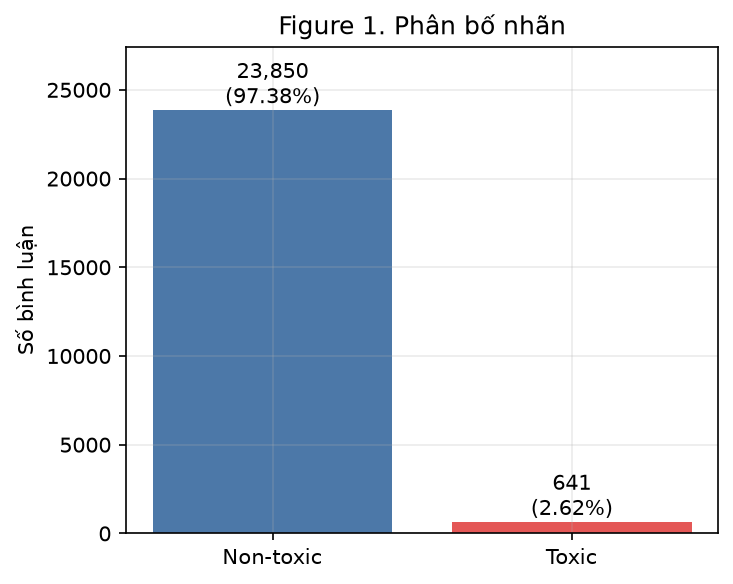

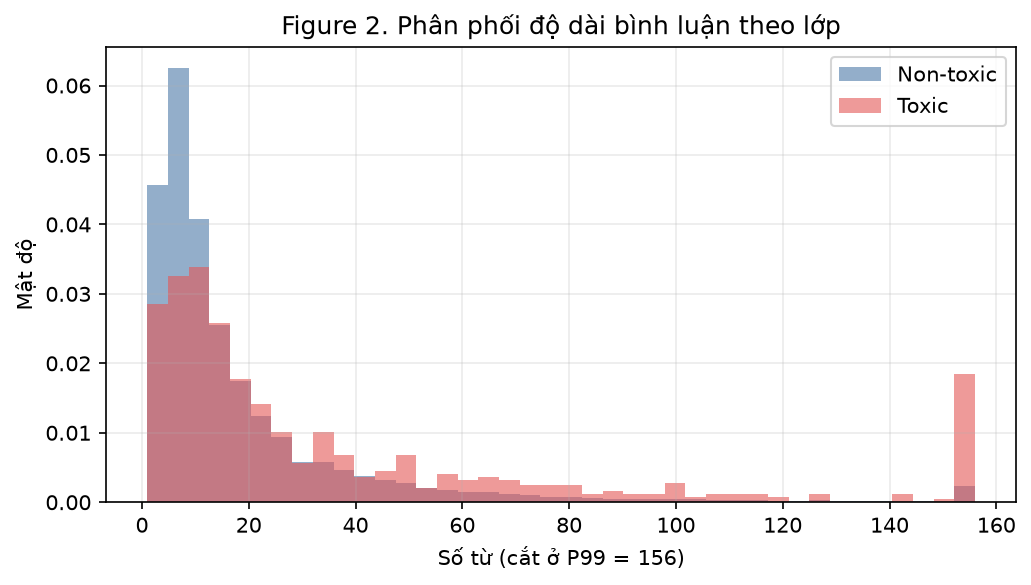

In [3]:
df_raw = pd.read_csv(DATA_PATH)
need_cols = {'id_comment', 'comment', 'label'}
assert need_cols <= set(df_raw.columns), f'Thiếu cột: {need_cols - set(df_raw.columns)}'

n_rows0 = len(df_raw)
quality = {
    'Tổng số dòng': n_rows0,
    'Thiếu comment': int(df_raw['comment'].isnull().sum()),
    'Thiếu label': int(df_raw['label'].isnull().sum()),
    'Comment rỗng (sau strip)': int((df_raw['comment'].astype(str).str.strip() == '').sum()),
    'Nhãn không hợp lệ': int((~df_raw['label'].isin(['toxic', 'non-toxic'])).sum() - df_raw['label'].isnull().sum()),
    'Trùng id_comment': int(df_raw['id_comment'].duplicated().sum()),
}
print('=== KIỂM TRA CHẤT LƯỢNG DỮ LIỆU GỐC ===')
for k, v in quality.items():
    print(f'{k:28s}: {v:,}')

df_raw = df_raw.dropna(subset=['comment', 'label']).copy()
df_raw = df_raw[df_raw['label'].isin(['toxic', 'non-toxic'])].copy()
df_raw['label_num'] = (df_raw['label'] == 'toxic').astype(int)
df_raw['word_len'] = df_raw['comment'].astype(str).str.split().str.len()
print(f'\nSố dòng hợp lệ dùng tiếp: {len(df_raw):,} / {n_rows0:,}')

counts = df_raw['label_num'].value_counts().sort_index()
imbalance_ratio = counts[0] / counts[1]
df_dist = pd.DataFrame({'Số lượng': counts.values, 'Tỷ lệ (%)': (counts / counts.sum() * 100).round(2).values},
                       index=['Non-toxic (0)', 'Toxic (1)'])
print('\n=== PHÂN BỐ NHÃN TOÀN CỤC ===')
print(df_dist)
print(f'Tỷ lệ mất cân bằng: {imbalance_ratio:.2f} : 1')

len_stats = df_raw.groupby('label_num')['word_len'].agg(
    mean='mean', median='median', p90=lambda s: s.quantile(0.9)).round(2)
len_stats.index = ['Non-toxic (0)', 'Toxic (1)']
print('\n=== ĐỘ DÀI BÌNH LUẬN (SỐ TỪ) ===')
print(len_stats)

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Non-toxic', 'Toxic'], counts.values, color=['#4C78A8', '#E45756'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({v / counts.sum() * 100:.2f}%)', ha='center', va='bottom')
ax.set_ylabel('Số bình luận'); ax.set_title('Figure 1. Phân bố nhãn'); ax.set_ylim(0, counts.max() * 1.15)
savefig('fig1_label_distribution.png')

cap = df_raw['word_len'].quantile(0.99)
fig, ax = plt.subplots(figsize=(7, 4))
for lab, name, col in [(0, 'Non-toxic', '#4C78A8'), (1, 'Toxic', '#E45756')]:
    ax.hist(df_raw.loc[df_raw.label_num == lab, 'word_len'].clip(upper=cap), bins=40, alpha=0.6,
            density=True, label=name, color=col)
ax.set_xlabel(f'Số từ (cắt ở P99 = {cap:.0f})'); ax.set_ylabel('Mật độ'); ax.legend()
ax.set_title('Figure 2. Phân phối độ dài bình luận theo lớp')
savefig('fig2_text_length_distribution.png')

print('\n=== MẪU BÌNH LUẬN (ngẫu nhiên, cố định seed) ===')
for lab, name in [(0, 'NON-TOXIC'), (1, 'TOXIC')]:
    print(f'\n[{name}]')
    for i, c in enumerate(df_raw[df_raw.label_num == lab]['comment'].sample(3, random_state=RANDOM_STATE), 1):
        print(f'  [{i}] {str(c)[:220]}')

## PHẦN 3. DATA CLEANING VÀ PREPROCESSING

**Thay đổi quan trọng về chống rò rỉ:** bản cũ chia Train/Test trước rồi mới khử trùng lặp trong Dev, nên còn 67 mẫu Test trùng nội dung với Dev. Bản này làm ngược lại:

1. Tiền xử lý toàn bộ bình luận (hàm `clean_text` không học gì từ dữ liệu nên không gây rò rỉ).
2. Loại bình luận rỗng sau tiền xử lý.
3. Loại các nhóm trùng nội dung mà **nhãn mâu thuẫn nhau** (nhãn không đáng tin), giữ một bản đại diện cho các nhóm trùng còn lại.
4. Chỉ sau đó mới chia Dev/Test, nên Dev và Test không thể trùng nội dung chính xác.

In [4]:
df = df_raw[['id_comment', 'comment', 'label_num']].copy()
df['clean'] = df['comment'].map(clean_text)

n_all = len(df)
empty_mask = df['clean'] == ''
n_empty = int(empty_mask.sum())
df = df[~empty_mask].copy()

grp = df.groupby('clean')['label_num'].agg(n='size', n_labels='nunique')
conflict_texts = grp.index[grp['n_labels'] > 1]
n_conflict_groups = len(conflict_texts)
conflict_mask = df['clean'].isin(conflict_texts)
n_conflict_rows = int(conflict_mask.sum())
df = df[~conflict_mask].copy()

n_dup_redundant = int(df.duplicated('clean', keep='first').sum())
df = df.drop_duplicates('clean', keep='first').reset_index(drop=True)

print('=== LÀM SẠCH SAU TIỀN XỬ LÝ (TOÀN BỘ DỮ LIỆU, TRƯỚC KHI CHIA) ===')
print(f'Số mẫu ban đầu:                               {n_all:,}')
print(f'Loại: bình luận rỗng sau tiền xử lý:          {n_empty:,}')
print(f'Loại: nhóm trùng nội dung nhưng nhãn mâu thuẫn: {n_conflict_groups:,} nhóm ({n_conflict_rows:,} dòng)')
print(f'Loại: bản sao thừa của các nhóm trùng nhất quán: {n_dup_redundant:,}')
print(f'Số mẫu dùng cho thực nghiệm:                  {len(df):,}')
print(f'Phân bố nhãn: Non-toxic = {(df.label_num == 0).sum():,}, Toxic = {(df.label_num == 1).sum():,} '
      f'({df.label_num.mean() * 100:.2f}% Toxic)')

=== LÀM SẠCH SAU TIỀN XỬ LÝ (TOÀN BỘ DỮ LIỆU, TRƯỚC KHI CHIA) ===
Số mẫu ban đầu:                               24,491
Loại: bình luận rỗng sau tiền xử lý:          21
Loại: nhóm trùng nội dung nhưng nhãn mâu thuẫn: 1 nhóm (2 dòng)
Loại: bản sao thừa của các nhóm trùng nhất quán: 214
Số mẫu dùng cho thực nghiệm:                  24,254
Phân bố nhãn: Non-toxic = 23,616, Toxic = 638 (2.63% Toxic)


## PHẦN 4. DATA SPLITTING VÀ EXPERIMENT DESIGN

* Chia Dev 80% / Test 20% có phân tầng theo nhãn, **khóa Test** từ đây: không dùng Test cho bất kỳ quyết định nào (chọn mô hình, tuning, dò ngưỡng).
* Vectorizer luôn nằm **trong** `Pipeline` và được fit lại trên phần Train của từng fold.
* Dùng chung một bộ 15 lượt chia (3 lần lặp × 5 fold) cho mọi so sánh, nên các so sánh là *paired*. Lượt lặp đầu tiên (5 fold) dùng cho baseline và tuning.
* Kiểm tra thêm **near-duplicate** (cosine TF-IDF ≥ ngưỡng) giữa Test và Dev: các mẫu gần giống nhau nhưng không trùng hoàn toàn cũng có thể làm Test lạc quan.

In [5]:
dev, test = train_test_split(df, test_size=TEST_SIZE, stratify=df['label_num'], random_state=RANDOM_STATE)
dev, test = dev.reset_index(drop=True), test.reset_index(drop=True)

# Kiểm tra giao thoa chính xác: phải bằng 0 theo cách xây dựng.
overlap = set(dev['clean']) & set(test['clean'])
assert len(overlap) == 0, 'Dev và Test còn trùng nội dung!'

X_dev = dev['clean'].to_numpy(dtype=object)
y_dev = dev['label_num'].to_numpy()
X_test = test['clean'].to_numpy(dtype=object)
y_test = test['label_num'].to_numpy()

# Kiểm tra near-duplicate Test -> Dev (chỉ để kiểm toán, vectorizer này chỉ fit trên Dev)
def max_cosine_to_dev(dev_texts, test_texts, chunk=200):
    v = TfidfVectorizer(sublinear_tf=True)
    A = v.fit_transform(dev_texts).T.tocsr()
    B = v.transform(test_texts)
    out = np.zeros(B.shape[0])
    for i in range(0, B.shape[0], chunk):
        out[i:i + chunk] = (B[i:i + chunk] @ A).max(axis=1).toarray().ravel()
    return out

test['max_cos_to_dev'] = max_cosine_to_dev(X_dev, X_test)
test['near_dup'] = test['max_cos_to_dev'] >= NEAR_DUP_COS

print('=== CHIA DỮ LIỆU ===')
print(f'Dev:  {len(dev):,} mẫu (Toxic {y_dev.sum():,} = {y_dev.mean() * 100:.2f}%)')
print(f'Test: {len(test):,} mẫu (Toxic {y_test.sum():,} = {y_test.mean() * 100:.2f}%)')
print(f'Giao thoa nội dung chính xác Dev-Test: {len(overlap)} (đã assert = 0)')
print(f'Near-duplicate (cosine >= {NEAR_DUP_COS}): {int(test.near_dup.sum())} mẫu Test '
      f'({test.near_dup.mean() * 100:.2f}%), trong đó Toxic: {int((test.near_dup & (test.label_num == 1)).sum())}')

dev[['id_comment', 'label_num']].to_csv(DATA_DIR / 'dev_ids.csv', index=False)
test[['id_comment', 'label_num', 'near_dup']].to_csv(DATA_DIR / 'test_ids.csv', index=False)

# ---- 15 lượt chia dùng chung cho mọi so sánh ----------------------------------
SPLITS_ALL = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS,
                                          random_state=RANDOM_STATE).split(X_dev, y_dev))
SPLITS_1 = SPLITS_ALL[:N_SPLITS]
n_train_cv, n_test_cv = len(SPLITS_ALL[0][0]), len(SPLITS_ALL[0][1])
print(f'\nCV: {len(SPLITS_ALL)} lượt chia ({N_REPEATS} x {N_SPLITS}); mỗi lượt Train = {n_train_cv:,}, Val = {n_test_cv:,}')

=== CHIA DỮ LIỆU ===
Dev:  19,403 mẫu (Toxic 510 = 2.63%)
Test: 4,851 mẫu (Toxic 128 = 2.64%)
Giao thoa nội dung chính xác Dev-Test: 0 (đã assert = 0)
Near-duplicate (cosine >= 0.9): 339 mẫu Test (6.99%), trong đó Toxic: 3

CV: 15 lượt chia (3 x 5); mỗi lượt Train = 15,522, Val = 3,881


In [6]:
# ---- Các hàm dùng chung cho toàn bộ thực nghiệm ------------------------------
def make_vectorizer(kind, ngram=(1, 2)):
    common = dict(ngram_range=ngram, min_df=2, max_features=50000)
    return TfidfVectorizer(sublinear_tf=True, **common) if kind == 'tfidf' else CountVectorizer(**common)

def make_classifier(algo, C=1.0, class_weight='balanced'):
    if algo == 'MultinomialNB':
        return MultinomialNB()
    if algo == 'ComplementNB':
        return ComplementNB()
    if algo == 'LogisticRegression':
        return LogisticRegression(C=C, class_weight=class_weight, solver='liblinear', max_iter=2000)
    if algo == 'LinearSVC':
        return LinearSVC(C=C, class_weight=class_weight, max_iter=10000, random_state=RANDOM_STATE)
    if algo == 'SGDClassifier':
        return SGDClassifier(loss='hinge', alpha=1e-4, class_weight=class_weight, max_iter=2000,
                             tol=1e-3, random_state=RANDOM_STATE)
    raise ValueError(algo)

def build_pipe(spec):
    return Pipeline([
        ('vec', make_vectorizer(spec['vec'], spec.get('ngram', (1, 2)))),
        ('clf', make_classifier(spec['algo'], spec.get('C', 1.0), spec.get('class_weight', 'balanced'))),
    ])

def get_scores(model, X):
    # Điểm xếp hạng: decision_function nếu có, ngược lại xác suất lớp Toxic.
    return model.decision_function(X) if hasattr(model, 'decision_function') else model.predict_proba(X)[:, 1]

METRIC_COLS = ['toxic_f1', 'toxic_precision', 'toxic_recall', 'macro_f1', 'pr_auc', 'roc_auc']

def _fit_eval(spec, X, y, tr, va, rep, fold):
    pipe = build_pipe(spec).fit(X[tr], y[tr])
    s, pred, yv = get_scores(pipe, X[va]), pipe.predict(X[va]), y[va]
    m = dict(repeat=rep, fold=fold,
             toxic_f1=f1_score(yv, pred, zero_division=0),
             toxic_precision=precision_score(yv, pred, zero_division=0),
             toxic_recall=recall_score(yv, pred, zero_division=0),
             macro_f1=f1_score(yv, pred, average='macro', zero_division=0),
             pr_auc=average_precision_score(yv, s), roc_auc=roc_auc_score(yv, s))
    return m, va, s

def run_cv(spec, X, y, splits, n_splits=N_SPLITS):
    # Trả về: bảng metric từng lượt, và điểm OOF có dạng [số lần lặp, n_mẫu].
    res = Parallel(n_jobs=N_JOBS)(
        delayed(_fit_eval)(spec, X, y, tr, va, i // n_splits, i % n_splits) for i, (tr, va) in enumerate(splits))
    folds = pd.DataFrame([r[0] for r in res])
    oof = np.full((len(splits) // n_splits, len(y)), np.nan)
    for m, va, s in res:
        oof[m['repeat'], va] = s
    return folds, oof

def best_f1_threshold(y_true, scores):
    # Ngưỡng cực đại hóa F1 lớp Toxic (quy tắc dự đoán: score >= ngưỡng).
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(t[i]), float(f1[i]), float(p[i]), float(r[i])

def threshold_metrics(y_true, scores, thr):
    pred = (scores >= thr).astype(int)
    return dict(threshold=thr, precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred, zero_division=0), f1=f1_score(y_true, pred, zero_division=0))

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    spread = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return max(0.0, centre - spread), min(1.0, centre + spread)

def corrected_ttest(d, n_train, n_test):
    # t-test cặp có hiệu chỉnh Nadeau & Bengio (2003) cho các lượt CV chồng lấn dữ liệu.
    d = np.asarray(d, dtype=float)
    J, mean, var = len(d), d.mean(), d.var(ddof=1)
    if var == 0:
        return mean, np.nan, np.nan
    t = mean / math.sqrt((1 / J + n_test / n_train) * var)
    return mean, t, 2 * stats.t.sf(abs(t), J - 1)

def boxplot(ax, data, labels):
    # Tương thích mọi phiên bản matplotlib (tham số `labels` đã bị đổi tên/loại bỏ ở bản mới).
    ax.boxplot(data)
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels)

def summarize(folds):
    out = {}
    for m in METRIC_COLS:
        out[f'{m}_mean'], out[f'{m}_std'] = folds[m].mean(), folds[m].std(ddof=1)
    return out

# Kiểm thử nhanh: pipeline chạy được trên 1 lượt chia, không rò rỉ vì vectorizer nằm trong pipeline.
_tr, _va = SPLITS_1[0]
_p = build_pipe(dict(vec='tfidf', algo='LinearSVC')).fit(X_dev[_tr], y_dev[_tr])
print('Pipeline mẫu:', [n for n, _ in _p.steps], '| số đặc trưng học từ Train fold 0:', len(_p.named_steps['vec'].vocabulary_))
print('Mọi vectorizer chỉ được fit trên Train của từng fold (nằm trong Pipeline).')

Pipeline mẫu: ['vec', 'clf'] | số đặc trưng học từ Train fold 0: 37857
Mọi vectorizer chỉ được fit trên Train của từng fold (nằm trong Pipeline).


## PHẦN 5. BASELINE EXPERIMENTS

So sánh 5 thuật toán × 2 cách biểu diễn (BoW, TF-IDF) trên 5-fold CV của tập Dev, cấu hình cơ sở: n-gram (1,2), `C=1`, `class_weight='balanced'` (với mô hình hỗ trợ).

Cột `Mean_Toxic_F1` đo ở ngưỡng mặc định của từng mô hình. `Mean_PR_AUC` không phụ thuộc ngưỡng nên là tiêu chí xếp hạng chính. `OOF_Best_Toxic_F1` là F1 tốt nhất khi dò ngưỡng trên điểm OOF gộp: **con số này hơi lạc quan** vì ngưỡng được chọn trên chính các điểm đó, chỉ dùng để so sánh tương đối giữa các mô hình.

Hoàn tất 10 cấu hình trong 34s

=== BENCHMARK 5-FOLD CV TRÊN DEV (xếp theo PR-AUC) ===


,Vectorizer,Algorithm,Mean_Macro_F1,Std_Macro_F1,Mean_Toxic_F1,Std_Toxic_F1,Mean_Toxic_Precision,Mean_Toxic_Recall,Mean_PR_AUC,Std_PR_AUC,OOF_Best_Toxic_F1
0,TF-IDF,LinearSVC,0.8631,0.0273,0.7327,0.0537,0.8182,0.6667,0.7967,0.0192,0.7416
1,TF-IDF,SGDClassifier,0.8630,0.0227,0.7332,0.0444,0.7360,0.7314,0.7730,0.0223,0.7382
2,TF-IDF,LogisticRegression,0.8205,0.0101,0.6524,0.0197,0.5574,0.7882,0.7418,0.0246,0.7032
3,BoW,LogisticRegression,0.8412,0.0222,0.6908,0.0432,0.6857,0.6961,0.7071,0.0270,0.7063
4,BoW,LinearSVC,0.8459,0.0238,0.6992,0.0464,0.7739,0.6392,0.6914,0.0340,0.7011
5,BoW,SGDClassifier,0.7780,0.0149,0.5679,0.0290,0.5598,0.5784,0.5626,0.0319,0.5741
6,BoW,MultinomialNB,0.7098,0.0235,0.4323,0.0462,0.5452,0.3588,0.3362,0.0497,0.4467
7,BoW,ComplementNB,0.6666,0.0196,0.3571,0.0382,0.2825,0.4863,0.3342,0.0476,0.4467
8,TF-IDF,MultinomialNB,0.5126,0.0095,0.0383,0.0189,1.0000,0.0196,0.2284,0.0177,0.2791
9,TF-IDF,ComplementNB,0.6311,0.0213,0.2758,0.0418,0.4791,0.1941,0.2284,0.0177,0.2791


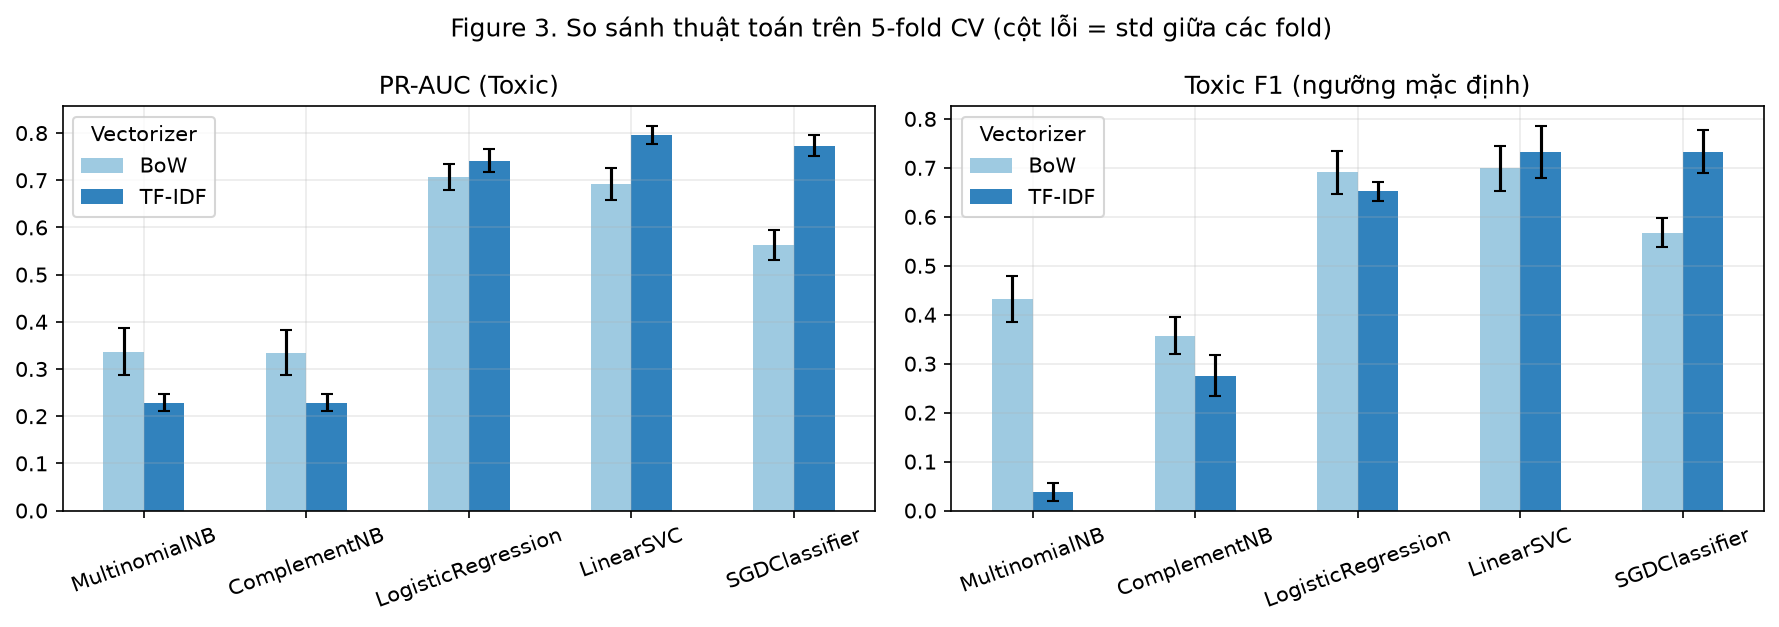

In [7]:
ALGOS = ['MultinomialNB', 'ComplementNB', 'LogisticRegression', 'LinearSVC', 'SGDClassifier']
rows = []
t0 = time.time()
for vec in ['bow', 'tfidf']:
    for algo in ALGOS:
        spec = dict(vec=vec, algo=algo, ngram=(1, 2), C=1.0, class_weight='balanced')
        folds, oof = run_cv(spec, X_dev, y_dev, SPLITS_1)
        s = summarize(folds)
        rows.append({
            'Vectorizer': 'TF-IDF' if vec == 'tfidf' else 'BoW', 'Algorithm': algo,
            'Mean_Macro_F1': s['macro_f1_mean'], 'Std_Macro_F1': s['macro_f1_std'],
            'Mean_Toxic_F1': s['toxic_f1_mean'], 'Std_Toxic_F1': s['toxic_f1_std'],
            'Mean_Toxic_Precision': s['toxic_precision_mean'], 'Mean_Toxic_Recall': s['toxic_recall_mean'],
            'Mean_PR_AUC': s['pr_auc_mean'], 'Std_PR_AUC': s['pr_auc_std'],
            'OOF_Best_Toxic_F1': best_f1_threshold(y_dev, oof[0])[1],
        })
df_bench = pd.DataFrame(rows).sort_values('Mean_PR_AUC', ascending=False).reset_index(drop=True)
df_bench.to_csv(RESULTS_DIR / 'benchmark_summary.csv', index=False)
print(f'Hoàn tất {len(df_bench)} cấu hình trong {time.time() - t0:.0f}s\n')
print('=== BENCHMARK 5-FOLD CV TRÊN DEV (xếp theo PR-AUC) ===')
display(df_bench.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
piv_pr = df_bench.pivot(index='Algorithm', columns='Vectorizer', values='Mean_PR_AUC').loc[ALGOS]
piv_f1 = df_bench.pivot(index='Algorithm', columns='Vectorizer', values='Mean_Toxic_F1').loc[ALGOS]
err_f1 = df_bench.pivot(index='Algorithm', columns='Vectorizer', values='Std_Toxic_F1').loc[ALGOS]
err_pr = df_bench.pivot(index='Algorithm', columns='Vectorizer', values='Std_PR_AUC').loc[ALGOS]
for ax, piv, err, ttl in [(axes[0], piv_pr, err_pr, 'PR-AUC (Toxic)'), (axes[1], piv_f1, err_f1, 'Toxic F1 (ngưỡng mặc định)')]:
    piv.plot.bar(ax=ax, yerr=err, capsize=3, color=['#9ecae1', '#3182bd'], rot=20)
    ax.set_title(ttl); ax.set_xlabel('')
fig.suptitle('Figure 3. So sánh thuật toán trên 5-fold CV (cột lỗi = std giữa các fold)')
savefig('fig3_baseline_algorithms_comparison.png')

## PHẦN 6. MODEL OPTIMIZATION

### 6A. Ablation tiền xử lý

Cùng một mô hình (TF-IDF + LinearSVC, `C=1`, `balanced`), cùng 15 lượt chia, chỉ thay đổi văn bản đầu vào:
`1_Raw` (văn bản gốc) → `2_Minimal` (chuẩn hóa tối thiểu) → `3_Full` (tiền xử lý đầy đủ).
Hiệu số so với `1_Raw` được kiểm định bằng t-test cặp có hiệu chỉnh Nadeau–Bengio vì các lượt CV chồng lấn nhau.

In [8]:
dev_raw = dev['comment'].astype(str).to_numpy(dtype=object)
dev_min = np.array([minimal_clean(t) for t in dev_raw], dtype=object)
variants = {'1_Raw': dev_raw, '2_Minimal': dev_min, '3_Full': X_dev}
spec_abl = dict(vec='tfidf', algo='LinearSVC', ngram=(1, 2), C=1.0, class_weight='balanced')

abl_folds = {}
for name, Xv in variants.items():
    abl_folds[name], _ = run_cv(spec_abl, Xv, y_dev, SPLITS_ALL)

abl_rows = []
for name, fdf in abl_folds.items():
    row = {'Strategy': name}
    for m, lab in [('toxic_f1', 'F1'), ('toxic_precision', 'Precision'), ('toxic_recall', 'Recall'), ('pr_auc', 'PR_AUC')]:
        row[f'Mean_{lab}'], row[f'Std_{lab}'] = fdf[m].mean(), fdf[m].std(ddof=1)
        if name != '1_Raw':
            d, t, p = corrected_ttest(fdf[m].values - abl_folds['1_Raw'][m].values, n_train_cv, n_test_cv)
            row[f'Delta_{lab}_vs_Raw'], row[f'p_{lab}'] = d, p
    abl_rows.append(row)
df_abl = pd.DataFrame(abl_rows)
df_abl.to_csv(RESULTS_DIR / 'ablation_summary.csv', index=False)
print('=== ABLATION TIỀN XỬ LÝ (15 lượt CV, kiểm định Nadeau–Bengio) ===')
display(df_abl.round(4))

full_vs_raw = {m: corrected_ttest(abl_folds['3_Full'][m].values - abl_folds['1_Raw'][m].values, n_train_cv, n_test_cv)
               for m in ['toxic_f1', 'toxic_precision', 'toxic_recall', 'pr_auc']}
for m, (d, t, p) in full_vs_raw.items():
    print(f'3_Full - 1_Raw | {m:16s}: {d * 100:+.2f} điểm phần trăm (p = {p:.4f})')

=== ABLATION TIỀN XỬ LÝ (15 lượt CV, kiểm định Nadeau–Bengio) ===


,Strategy,Mean_F1,Std_F1,Mean_Precision,Std_Precision,Mean_Recall,Std_Recall,Mean_PR_AUC,Std_PR_AUC,Delta_F1_vs_Raw,p_F1,Delta_Precision_vs_Raw,p_Precision,Delta_Recall_vs_Raw,p_Recall,Delta_PR_AUC_vs_Raw,p_PR_AUC
0,1_Raw,0.7074,0.0339,0.8029,0.0357,0.6333,0.0422,0.7777,0.0289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2_Minimal,0.7076,0.0312,0.7986,0.0334,0.6366,0.0418,0.7833,0.0278,0.0003,0.9592,-0.0043,0.693,0.0033,0.4801,0.0057,0.0271
2,3_Full,0.7269,0.0324,0.8039,0.0303,0.6654,0.0491,0.7991,0.0209,0.0196,0.0196,0.0010,0.953,0.0320,0.0267,0.0214,0.1882


3_Full - 1_Raw | toxic_f1        : +1.96 điểm phần trăm (p = 0.0196)
3_Full - 1_Raw | toxic_precision : +0.10 điểm phần trăm (p = 0.9530)
3_Full - 1_Raw | toxic_recall    : +3.20 điểm phần trăm (p = 0.0267)
3_Full - 1_Raw | pr_auc          : +2.14 điểm phần trăm (p = 0.1882)


### 6B. Tối ưu siêu tham số cho LinearSVC (TF-IDF)

Lưới: n-gram ∈ {(1,1), (1,2)} × C ∈ {0.1, 0.5, 1, 2, 5} × class_weight ∈ {None, balanced}, trên 5-fold CV của Dev.
**Tiêu chí chọn cấu hình: PR-AUC trung bình cao nhất** (không phụ thuộc ngưỡng, vì ngưỡng sẽ được dò riêng ở Phần 8). Cột `Gap_in_Std` cho biết cấu hình đó kém cấu hình tốt nhất bao nhiêu lần độ lệch chuẩn; nếu gap nhỏ hơn 1 thì các cấu hình thực chất không phân biệt được với nhau về mặt thống kê.

In [9]:
grid_rows, grid_specs = [], []
t0 = time.time()
for ngram in [(1, 1), (1, 2)]:
    for C in [0.1, 0.5, 1.0, 2.0, 5.0]:
        for cw in [None, 'balanced']:
            spec = dict(vec='tfidf', algo='LinearSVC', ngram=ngram, C=C, class_weight=cw)
            folds, oof = run_cv(spec, X_dev, y_dev, SPLITS_1)
            s = summarize(folds)
            grid_specs.append(spec)
            grid_rows.append({'C': C, 'ngram_range': str(ngram), 'class_weight': str(cw),
                              'Mean_Toxic_F1': s['toxic_f1_mean'], 'Std_Toxic_F1': s['toxic_f1_std'],
                              'Mean_PR_AUC': s['pr_auc_mean'], 'Std_PR_AUC': s['pr_auc_std'],
                              'OOF_Best_Toxic_F1': best_f1_threshold(y_dev, oof[0])[1]})
df_grid = pd.DataFrame(grid_rows)
best_idx = int(df_grid['Mean_PR_AUC'].idxmax())
best_spec = grid_specs[best_idx]
df_grid['Gap_in_Std'] = (df_grid.loc[best_idx, 'Mean_PR_AUC'] - df_grid['Mean_PR_AUC']) / df_grid.loc[best_idx, 'Std_PR_AUC']
df_grid = df_grid.sort_values('Mean_PR_AUC', ascending=False).reset_index(drop=True)
df_grid.to_csv(RESULTS_DIR / 'hyperparameter_results.csv', index=False)
print(f'Hoàn tất {len(df_grid)} cấu hình trong {time.time() - t0:.0f}s\n')
print('=== TOP 8 CẤU HÌNH LINEARSVC (xếp theo PR-AUC) ===')
display(df_grid.head(8).round(4))
print('\nCấu hình được chọn:', best_spec)

Hoàn tất 20 cấu hình trong 36s

=== TOP 8 CẤU HÌNH LINEARSVC (xếp theo PR-AUC) ===


,C,ngram_range,class_weight,Mean_Toxic_F1,Std_Toxic_F1,Mean_PR_AUC,Std_PR_AUC,OOF_Best_Toxic_F1,Gap_in_Std
0,1.0,"(1, 2)",None,0.6446,0.0470,0.8104,0.0188,0.7543,0.0000
1,2.0,"(1, 2)",None,0.6814,0.0514,0.8080,0.0177,0.7561,0.1245
2,0.5,"(1, 2)",None,0.5827,0.0505,0.8073,0.0196,0.7478,0.1666
3,5.0,"(1, 2)",None,0.7017,0.0504,0.8025,0.0172,0.7515,0.4189
4,5.0,"(1, 2)",balanced,0.7188,0.0469,0.8012,0.0181,0.7500,0.4900
5,2.0,"(1, 2)",balanced,0.7286,0.0533,0.8003,0.0178,0.7478,0.5343
6,1.0,"(1, 2)",balanced,0.7327,0.0537,0.7967,0.0192,0.7416,0.7297
7,0.5,"(1, 2)",balanced,0.7199,0.0446,0.7867,0.0205,0.7366,1.2605



Cấu hình được chọn: {'vec': 'tfidf', 'algo': 'LinearSVC', 'ngram': (1, 2), 'C': 1.0, 'class_weight': None}


### 6C. BoW so với TF-IDF trên cấu hình đã chọn (15 lượt CV, paired)

Cùng một bộ siêu tham số, chỉ đổi cách biểu diễn. Kết quả TF-IDF của lượt chạy này cũng chính là dữ liệu cho phân tích ổn định (Phần 7) và dò ngưỡng (Phần 8).

=== BoW vs TF-IDF (cùng siêu tham số, 15 lượt CV) ===


,Metric,BoW,TF-IDF,TF-IDF - BoW,p (Nadeau–Bengio)
0,Toxic F1 (ngưỡng mặc định),0.7132 ± 0.0318,0.6402 ± 0.0376,-0.0730,0.0047
1,PR-AUC,0.7389 ± 0.0280,0.8140 ± 0.0180,+0.0751,0.0006
2,Toxic Recall,0.6248 ± 0.0362,0.4882 ± 0.0431,-0.1366,0.0000
3,Toxic Precision,0.8323 ± 0.0383,0.9348 ± 0.0266,+0.1025,0.0041


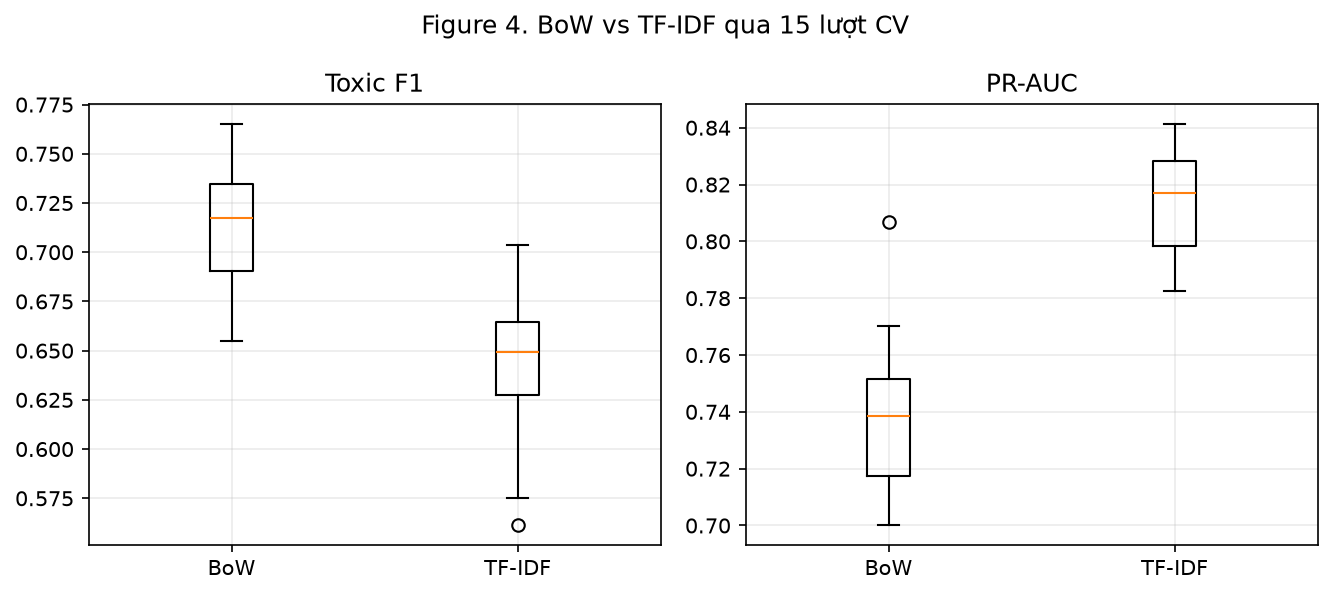

In [10]:
folds_best, oof_best = run_cv(best_spec, X_dev, y_dev, SPLITS_ALL)                      # TF-IDF
spec_bow = {**best_spec, 'vec': 'bow'}
folds_bow, _ = run_cv(spec_bow, X_dev, y_dev, SPLITS_ALL)                               # BoW

cmp_rows = []
bow_vs_tfidf = {}
for m, lab in [('toxic_f1', 'Toxic F1 (ngưỡng mặc định)'), ('pr_auc', 'PR-AUC'), ('toxic_recall', 'Toxic Recall'), ('toxic_precision', 'Toxic Precision')]:
    d, t, p = corrected_ttest(folds_best[m].values - folds_bow[m].values, n_train_cv, n_test_cv)
    bow_vs_tfidf[m] = (d, p)
    cmp_rows.append({'Metric': lab, 'BoW': f'{folds_bow[m].mean():.4f} ± {folds_bow[m].std(ddof=1):.4f}',
                     'TF-IDF': f'{folds_best[m].mean():.4f} ± {folds_best[m].std(ddof=1):.4f}',
                     'TF-IDF - BoW': f'{d:+.4f}', 'p (Nadeau–Bengio)': f'{p:.4f}'})
df_cmp = pd.DataFrame(cmp_rows)
df_cmp.to_csv(RESULTS_DIR / 'bow_vs_tfidf.csv', index=False)
print('=== BoW vs TF-IDF (cùng siêu tham số, 15 lượt CV) ===')
display(df_cmp)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, m, ttl in [(axes[0], 'toxic_f1', 'Toxic F1'), (axes[1], 'pr_auc', 'PR-AUC')]:
    boxplot(ax, [folds_bow[m], folds_best[m]], ['BoW', 'TF-IDF'])
    ax.set_title(ttl)
fig.suptitle('Figure 4. BoW vs TF-IDF qua 15 lượt CV')
savefig('fig4_bow_vs_tfidf_comparison.png')

## PHẦN 7. ROBUSTNESS AND STABILITY ANALYSIS

Phân tích độ phân tán của mô hình đã chọn qua 15 lượt đánh giá (3 lần lặp × 5 fold). Các chỉ số ở đây đo ở **ngưỡng mặc định**; hiệu quả của việc dịch ngưỡng được đo riêng ở Phần 8.

=== ĐỘ ỔN ĐỊNH CỦA MÔ HÌNH ĐÃ CHỌN QUA 15 LƯỢT ĐÁNH GIÁ ===


,Metric,Mean,Std (15 lượt),Min,Max,Std giữa 3 lần lặp (trung bình)
0,Toxic F1,0.6402,0.0376,0.5616,0.7037,0.0053
1,Toxic Precision,0.9348,0.0266,0.8730,0.9630,0.0090
2,Toxic Recall,0.4882,0.0431,0.4020,0.5588,0.0090
3,Macro F1,0.8164,0.0191,0.7766,0.8487,0.0026
4,PR-AUC,0.8140,0.0180,0.7824,0.8412,0.0036
5,ROC-AUC,0.9821,0.0050,0.9754,0.9936,0.0007



Độ biến thiên tương đối của Toxic F1 giữa các lượt: 5.9% (mỗi fold chỉ có khoảng 102 mẫu Toxic nên dao động giữa fold là đáng kể).


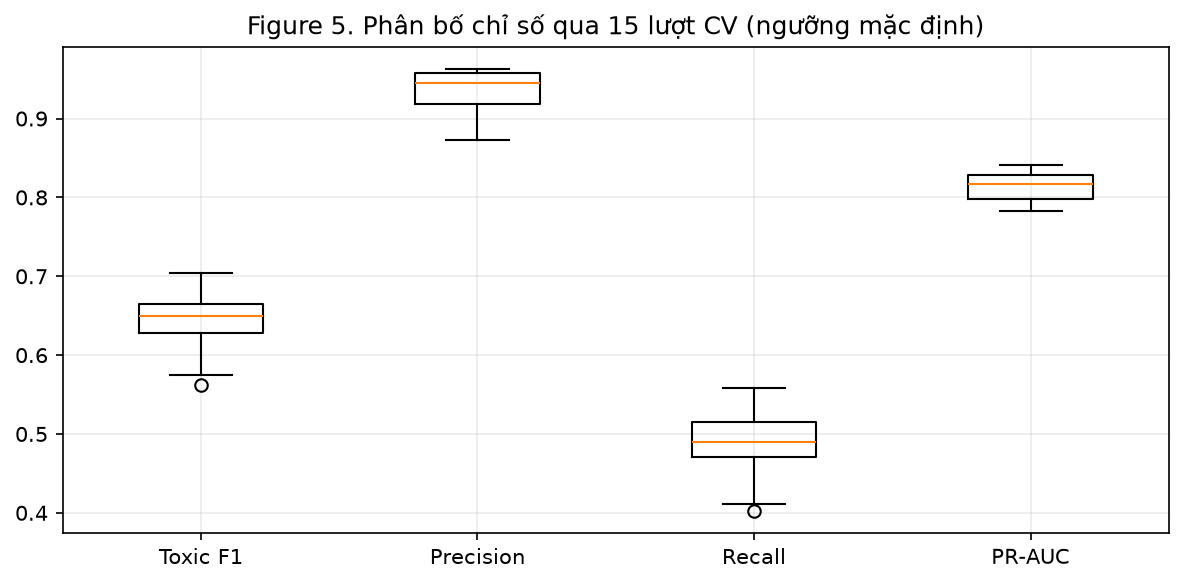

In [11]:
stab_rows = []
for m, lab in [('toxic_f1', 'Toxic F1'), ('toxic_precision', 'Toxic Precision'), ('toxic_recall', 'Toxic Recall'),
               ('macro_f1', 'Macro F1'), ('pr_auc', 'PR-AUC'), ('roc_auc', 'ROC-AUC')]:
    v = folds_best[m].values
    per_rep = folds_best.groupby('repeat')[m].mean().values
    stab_rows.append({'Metric': lab, 'Mean': v.mean(), 'Std (15 lượt)': v.std(ddof=1), 'Min': v.min(), 'Max': v.max(),
                      'Std giữa 3 lần lặp (trung bình)': per_rep.std(ddof=1)})
df_stab = pd.DataFrame(stab_rows)
df_stab.to_csv(RESULTS_DIR / 'stability_summary.csv', index=False)
print(f'=== ĐỘ ỔN ĐỊNH CỦA MÔ HÌNH ĐÃ CHỌN QUA {len(folds_best)} LƯỢT ĐÁNH GIÁ ===')
display(df_stab.round(4))

cv_f1_cv = df_stab.set_index('Metric').loc['Toxic F1']
print(f"\nĐộ biến thiên tương đối của Toxic F1 giữa các lượt: {cv_f1_cv['Std (15 lượt)'] / cv_f1_cv['Mean'] * 100:.1f}% "
      f"(mỗi fold chỉ có khoảng {int(y_dev.sum() / N_SPLITS)} mẫu Toxic nên dao động giữa fold là đáng kể).")

fig, ax = plt.subplots(figsize=(8, 4))
labs = ['toxic_f1', 'toxic_precision', 'toxic_recall', 'pr_auc']
boxplot(ax, [folds_best[m] for m in labs], ['Toxic F1', 'Precision', 'Recall', 'PR-AUC'])
ax.set_title('Figure 5. Phân bố chỉ số qua 15 lượt CV (ngưỡng mặc định)')
savefig('fig5_stability_analysis.png')

## PHẦN 8. THRESHOLD OPTIMIZATION

Lớp Toxic hiếm nên ngưỡng mặc định `0` của LinearSVC không tối ưu cho F1. Ngưỡng `θ*` được chọn **chỉ từ điểm OOF của Dev**: gộp điểm OOF của cả 3 lần lặp CV (mỗi mẫu có 3 điểm từ 3 mô hình khác nhau) rồi quét đường cong Precision-Recall để cực đại hóa F1. Test không được dùng ở bước này.

Lưu ý: điểm OOF đến từ mô hình huấn luyện trên 80% Dev, còn mô hình cuối huấn luyện trên 100% Dev, nên thang điểm có thể lệch nhẹ. Ngưỡng được kiểm tra độ ổn định bằng cách dò riêng từng lần lặp.

=== DÒ NGƯỠNG TRÊN OOF (DEV) ===
Ngưỡng mặc định θ = 0.0000 : Precision 0.9337 | Recall 0.4882 | F1 0.6412
Ngưỡng tối ưu   θ* = -0.4049: Precision 0.7543 | Recall 0.7523 | F1 0.7533
Ngưỡng tối ưu riêng từng lần lặp: [-0.3718, -0.4061, -0.4098]  (độ lệch chuẩn 0.0209)


431

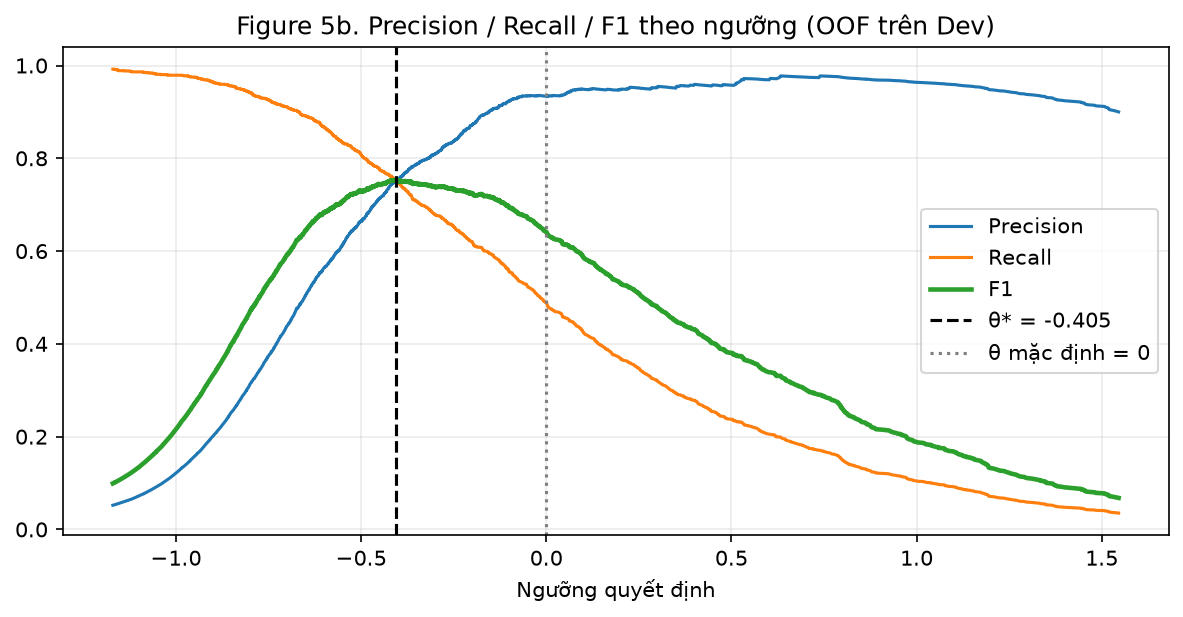

In [12]:
y_tile = np.tile(y_dev, N_REPEATS)
s_all = oof_best.ravel()
assert not np.isnan(s_all).any()

theta_star, f1_oof_star, p_oof_star, r_oof_star = best_f1_threshold(y_tile, s_all)
per_rep_thr = [best_f1_threshold(y_dev, oof_best[r])[0] for r in range(N_REPEATS)]
oof_default = threshold_metrics(y_tile, s_all, 0.0)
oof_opt = threshold_metrics(y_tile, s_all, theta_star)

print('=== DÒ NGƯỠNG TRÊN OOF (DEV) ===')
print(f'Ngưỡng mặc định θ = 0.0000 : Precision {oof_default["precision"]:.4f} | Recall {oof_default["recall"]:.4f} | F1 {oof_default["f1"]:.4f}')
print(f'Ngưỡng tối ưu   θ* = {theta_star:.4f}: Precision {oof_opt["precision"]:.4f} | Recall {oof_opt["recall"]:.4f} | F1 {oof_opt["f1"]:.4f}')
print(f'Ngưỡng tối ưu riêng từng lần lặp: {[round(t, 4) for t in per_rep_thr]}  (độ lệch chuẩn {np.std(per_rep_thr, ddof=1):.4f})')

p_c, r_c, t_c = precision_recall_curve(y_tile, s_all)
f1_c = 2 * p_c[:-1] * r_c[:-1] / np.clip(p_c[:-1] + r_c[:-1], 1e-12, None)
fig, ax = plt.subplots(figsize=(8, 4.2))
lo, hi = np.percentile(s_all, [50, 99.9])
msk = (t_c >= min(lo, theta_star - 0.5)) & (t_c <= hi)
ax.plot(t_c[msk], p_c[:-1][msk], label='Precision'); ax.plot(t_c[msk], r_c[:-1][msk], label='Recall')
ax.plot(t_c[msk], f1_c[msk], label='F1', lw=2.2)
ax.axvline(theta_star, color='k', ls='--', label=f'θ* = {theta_star:.3f}'); ax.axvline(0, color='gray', ls=':', label='θ mặc định = 0')
ax.set_xlabel('Ngưỡng quyết định'); ax.set_title('Figure 5b. Precision / Recall / F1 theo ngưỡng (OOF trên Dev)'); ax.legend()
savefig('fig5b_threshold_sweep.png')

best_config = {'spec': {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_spec.items()},
               'selection_criterion': 'max mean PR-AUC, 5-fold CV on Dev', 'optimal_threshold': theta_star,
               'threshold_rule': 'predict Toxic if decision_score >= optimal_threshold',
               'threshold_per_repeat': per_rep_thr}
(RESULTS_DIR / 'best_configuration.json').write_text(json.dumps(best_config, indent=2, ensure_ascii=False), encoding='utf-8')

## PHẦN 9. FINAL MODEL EVALUATION

Đánh giá **một lần duy nhất** trên Test đã khóa:

1. Huấn luyện mô hình đã chọn trên toàn bộ Dev.
2. Áp dụng ngưỡng `θ*` đã cố định từ Phần 8.
3. Báo cáo đầy đủ chỉ số, Wilson 95% CI (Accuracy / Precision / Recall) và bootstrap 95% CI (F1 / Macro F1 / PR-AUC).
4. Kiểm tra độ nhạy khi loại các mẫu near-duplicate.

In [13]:
final_pipe = build_pipe(best_spec).fit(X_dev, y_dev)
scores_test = get_scores(final_pipe, X_test)
pred_test = (scores_test >= theta_star).astype(int)

def full_metrics(y, pred, score):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
                macro_f1=f1_score(y, pred, average='macro'), weighted_f1=f1_score(y, pred, average='weighted'),
                pr_auc=average_precision_score(y, score), roc_auc=roc_auc_score(y, score),
                balanced_acc=balanced_accuracy_score(y, pred), mcc=matthews_corrcoef(y, pred),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

tm = full_metrics(y_test, pred_test, scores_test)
n_test_total, n_test_pos = len(y_test), int(y_test.sum())

# Bootstrap CI
rng = np.random.default_rng(RANDOM_STATE)
boot = {k: [] for k in ['f1', 'macro_f1', 'pr_auc']}
for _ in range(N_BOOT):
    idx = rng.integers(0, n_test_total, n_test_total)
    yb = y_test[idx]
    if yb.sum() == 0 or yb.sum() == len(yb):
        continue
    boot['f1'].append(f1_score(yb, pred_test[idx], zero_division=0))
    boot['macro_f1'].append(f1_score(yb, pred_test[idx], average='macro'))
    boot['pr_auc'].append(average_precision_score(yb, scores_test[idx]))
ci_boot = {k: tuple(np.percentile(v, [2.5, 97.5])) for k, v in boot.items()}
ci_acc = wilson_ci(tm['tp'] + tm['tn'], n_test_total)
ci_prec = wilson_ci(tm['tp'], tm['tp'] + tm['fp'])
ci_rec = wilson_ci(tm['tp'], tm['tp'] + tm['fn'])

report_rows = [
    ('Accuracy', tm['accuracy'], ci_acc, 'Wilson'),
    ('Toxic Precision', tm['precision'], ci_prec, 'Wilson'),
    ('Toxic Recall', tm['recall'], ci_rec, 'Wilson'),
    ('Toxic F1', tm['f1'], ci_boot['f1'], f'Bootstrap ({N_BOOT})'),
    ('Macro F1', tm['macro_f1'], ci_boot['macro_f1'], f'Bootstrap ({N_BOOT})'),
    ('PR-AUC', tm['pr_auc'], ci_boot['pr_auc'], f'Bootstrap ({N_BOOT})'),
    ('Weighted F1', tm['weighted_f1'], (np.nan, np.nan), ''),
    ('ROC-AUC', tm['roc_auc'], (np.nan, np.nan), ''),
    ('Balanced Accuracy', tm['balanced_acc'], (np.nan, np.nan), ''),
    ('MCC', tm['mcc'], (np.nan, np.nan), ''),
]
df_report = pd.DataFrame([{'Metric': n, 'Value': v, 'CI95_low': c[0], 'CI95_high': c[1], 'CI_method': m}
                          for n, v, c, m in report_rows])
df_report.to_csv(RESULTS_DIR / 'test_metrics.csv', index=False)

print(f'=== KẾT QUẢ CUỐI TRÊN TEST (N = {n_test_total:,}; Toxic = {n_test_pos}; θ* = {theta_star:.4f}) ===')
display(df_report.round(4))
print(f"Confusion matrix: TP = {tm['tp']}, FP = {tm['fp']}, FN = {tm['fn']}, TN = {tm['tn']}\n")
print(classification_report(y_test, pred_test, target_names=['non-toxic', 'toxic'], digits=4))
pd.DataFrame(classification_report(y_test, pred_test, target_names=['non-toxic', 'toxic'], output_dict=True)).T.to_csv(
    RESULTS_DIR / 'test_classification_report.csv')

# Tham khảo: ngưỡng mặc định (KHÔNG dùng để chọn mô hình hay ngưỡng)
tm_default = full_metrics(y_test, (scores_test >= 0).astype(int), scores_test)
print(f"[Tham khảo] Test ở ngưỡng mặc định 0: Precision {tm_default['precision']:.4f} | Recall {tm_default['recall']:.4f} | F1 {tm_default['f1']:.4f}")

# Độ nhạy: loại các mẫu near-duplicate
keep = ~test['near_dup'].to_numpy()
n_keep, n_keep_pos = int(keep.sum()), int(y_test[keep].sum())
if n_keep_pos >= 10:
    tm_nodup = full_metrics(y_test[keep], pred_test[keep], scores_test[keep])
    d_f1_nodup = tm_nodup['f1'] - tm['f1']
    print(f"[Độ nhạy] Loại {int((~keep).sum())} mẫu near-duplicate (N = {n_keep:,}, Toxic = {n_keep_pos}): "
          f"Precision {tm_nodup['precision']:.4f} | Recall {tm_nodup['recall']:.4f} | F1 {tm_nodup['f1']:.4f} "
          f"(chênh F1 = {d_f1_nodup:+.4f})")
else:
    tm_nodup, d_f1_nodup = None, float('nan')
    print(f"[Độ nhạy] Loại near-duplicate chỉ còn {n_keep} mẫu ({n_keep_pos} Toxic): quá ít để đánh giá lại.")

df_pred = test[['id_comment', 'comment', 'clean', 'label_num', 'near_dup']].rename(
    columns={'clean': 'clean_comment', 'label_num': 'true_label'}).copy()
df_pred['decision_score'] = scores_test
df_pred['predicted_label'] = pred_test
df_pred.to_csv(RESULTS_DIR / 'test_predictions.csv', index=False)

# Lưu mô hình
model_bundle = {'pipeline': final_pipe, 'threshold': theta_star, 'spec': best_spec,
                'preprocess': 'toxic_preprocess.clean_text', 'sklearn_version': sklearn.__version__}
joblib.dump(model_bundle, MODELS_DIR / 'best_model.joblib')
print(f"\nĐã lưu mô hình: {MODELS_DIR / 'best_model.joblib'}")

=== KẾT QUẢ CUỐI TRÊN TEST (N = 4,851; Toxic = 128; θ* = -0.4049) ===


,Metric,Value,CI95_low,CI95_high,CI_method
0,Accuracy,0.9878,0.9843,0.9906,Wilson
1,Toxic Precision,0.7760,0.6953,0.8402,Wilson
2,Toxic Recall,0.7578,0.6768,0.8238,Wilson
3,Toxic F1,0.7668,0.7027,0.8252,Bootstrap (1000)
4,Macro F1,0.8803,0.8473,0.9099,Bootstrap (1000)
5,PR-AUC,0.8405,0.7813,0.8952,Bootstrap (1000)
6,Weighted F1,0.9878,NaN,NaN,
7,ROC-AUC,0.9832,NaN,NaN,
8,Balanced Accuracy,0.8759,NaN,NaN,
9,MCC,0.7606,NaN,NaN,


Confusion matrix: TP = 97, FP = 28, FN = 31, TN = 4695

              precision    recall  f1-score   support

   non-toxic     0.9934    0.9941    0.9938      4723
       toxic     0.7760    0.7578    0.7668       128

    accuracy                         0.9878      4851
   macro avg     0.8847    0.8759    0.8803      4851
weighted avg     0.9877    0.9878    0.9878      4851

[Tham khảo] Test ở ngưỡng mặc định 0: Precision 0.9841 | Recall 0.4844 | F1 0.6492
[Độ nhạy] Loại 339 mẫu near-duplicate (N = 4,512, Toxic = 125): Precision 0.7705 | Recall 0.7520 | F1 0.7611 (chênh F1 = -0.0057)



Đã lưu mô hình: D:\file moi btl;\BENCHMARK_TOXIC\models\best_model.joblib


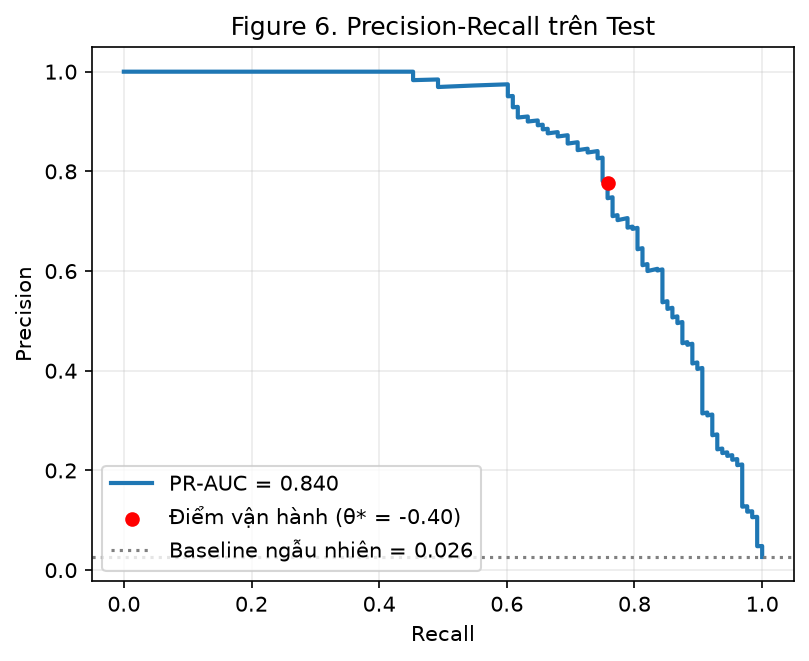

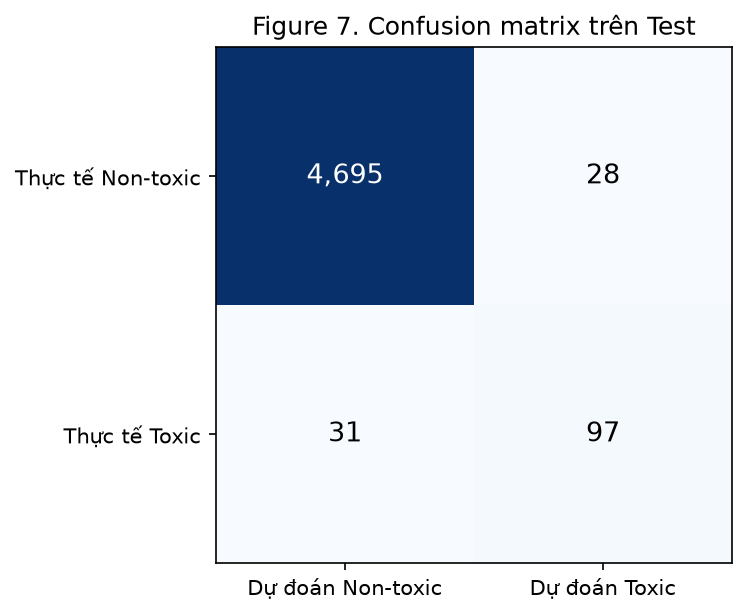

In [14]:
# Figure 6: PR curve trên Test; Figure 7: Confusion matrix
p_t, r_t, _ = precision_recall_curve(y_test, scores_test)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(r_t, p_t, lw=2, label=f"PR-AUC = {tm['pr_auc']:.3f}")
ax.scatter([tm['recall']], [tm['precision']], color='red', zorder=5, label=f'Điểm vận hành (θ* = {theta_star:.2f})')
ax.axhline(y_test.mean(), color='gray', ls=':', label=f'Baseline ngẫu nhiên = {y_test.mean():.3f}')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Figure 6. Precision-Recall trên Test'); ax.legend(loc='lower left')
savefig('fig6_precision_recall_curve.png')

cm = np.array([[tm['tn'], tm['fp']], [tm['fn'], tm['tp']]])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=13)
ax.set_xticks([0, 1], ['Dự đoán Non-toxic', 'Dự đoán Toxic']); ax.set_yticks([0, 1], ['Thực tế Non-toxic', 'Thực tế Toxic'])
ax.set_title('Figure 7. Confusion matrix trên Test'); ax.grid(False)
savefig('fig7_confusion_matrix.png')

## PHẦN 10. ERROR ANALYSIS AND MODEL INTERPRETATION

1. **Giải thích từng ca lỗi:** với mỗi False Positive / False Negative, liệt kê các n-gram đóng góp lớn nhất vào điểm quyết định (`tf-idf × trọng số`). Đây là giải thích tự động từ mô hình, không phải nhận định ngôn ngữ học của người đọc.
2. **Phân tích theo độ dài** bình luận.
3. **Trọng số đặc trưng** (Figure 8).
4. **Kiểm toán nhãn:** xuất `label_audit_sample.csv` gồm toàn bộ ca lỗi và một mẫu ca đúng để người kiểm tra thủ công. Nhãn do LLM gán, nên một phần "lỗi mô hình" có thể là lỗi nhãn.
5. **Độ trễ suy luận** đo thực tế.

In [15]:
vec_f, clf_f = final_pipe.named_steps['vec'], final_pipe.named_steps['clf']
feat_names = np.array(vec_f.get_feature_names_out())
coef = clf_f.coef_.ravel()

def explain(text, k=4):
    x = vec_f.transform([text])
    if x.nnz == 0:
        return '(không có đặc trưng nào trong từ điển)'
    idx, val = x.indices, x.data
    contrib = val * coef[idx]
    top = np.argsort(-np.abs(contrib))[:k]
    return '; '.join(f'{feat_names[idx[i]]} ({contrib[i]:+.2f})' for i in top)

df_pred['error_type'] = np.select([(df_pred.true_label == 0) & (df_pred.predicted_label == 1),
                                   (df_pred.true_label == 1) & (df_pred.predicted_label == 0)],
                                  ['False_Positive', 'False_Negative'], default='Correct')
df_err = df_pred[df_pred.error_type != 'Correct'].copy()
df_err['top_ngram_contributions'] = df_err['clean_comment'].map(explain)
df_err.sort_values(['error_type', 'decision_score'], ascending=[True, False]).to_csv(RESULTS_DIR / 'error_analysis.csv', index=False)

fps = df_err[df_err.error_type == 'False_Positive'].sort_values('decision_score', ascending=False)
fns = df_err[df_err.error_type == 'False_Negative'].sort_values('decision_score', ascending=True)
print(f'Tổng False Positive: {len(fps)} | Tổng False Negative: {len(fns)}')

def show_cases(dfc, title, n=5):
    print(f'\n--- {title} ---')
    for i, (_, r) in enumerate(dfc.head(n).iterrows(), 1):
        print(f"[{i}] id={r['id_comment']} | điểm={r['decision_score']:+.3f}")
        print(f"    Gốc:      {str(r['comment'])[:200]}")
        print(f"    Đóng góp: {r['top_ngram_contributions']}")

show_cases(fps, 'FALSE POSITIVE có điểm cao nhất (mô hình rất chắc chắn nhưng nhãn là Non-toxic)')
show_cases(fns, 'FALSE NEGATIVE có điểm thấp nhất (mô hình rất chắc chắn là Non-toxic nhưng nhãn là Toxic)')

Tổng False Positive: 28 | Tổng False Negative: 31

--- FALSE POSITIVE có điểm cao nhất (mô hình rất chắc chắn nhưng nhãn là Non-toxic) ---
[1] id=24363 | điểm=+0.051
    Gốc:      ko thui bị chửi sml kk
    Đóng góp: lồn (+0.85); bị (+0.17); chửi (+0.16); bị chửi (+0.07)
[2] id=23002 | điểm=-0.014
    Gốc:      Ko đâu nếu có gì thay đổi là bọn bò ngoi lên húc rồi
    Đóng góp: bò (+0.45); bọn (+0.40); húc (+0.13); có gì (-0.12)
[3] id=21957 | điểm=-0.155
    Gốc:      Chứ sự thật nằm trên mõm tụi mày à
    Đóng góp: mày (+0.44); tụi (+0.28); mõm (+0.17); sự thật (+0.15)
[4] id=24351 | điểm=-0.172
    Gốc:      "Đừng Ngu như CƯỜNG"
    Đóng góp: ngu (+1.11); đừng (-0.13); như (+0.09); như cường (-0.01)
[5] id=17814 | điểm=-0.184
    Gốc:      Có mấy con bò đụng nó thôi chứ ai quan tâm
    Đóng góp: bò (+0.45); con bò (-0.25); con (+0.19); mấy con (+0.10)

--- FALSE NEGATIVE có điểm thấp nhất (mô hình rất chắc chắn là Non-toxic nhưng nhãn là Toxic) ---
[1] id=22708 | điểm=-1.200
    Gốc:

Đã xuất 109 bình luận vào label_audit_sample.csv (điền cột human_label rồi tính tỷ lệ bất đồng với nhãn LLM).

=== HIỆU NĂNG THEO ĐỘ DÀI BÌNH LUẬN (TEST) ===


,Số từ,N,N_Toxic,Recall,Precision
0,"(0.999, 6.0]",1415,18,0.9444,0.6538
1,"(6.0, 11.0]",1183,23,0.6957,0.6957
2,"(11.0, 22.0]",1059,27,0.7778,0.9130
3,"(22.0, 1102.0]",1194,60,0.7167,0.8113


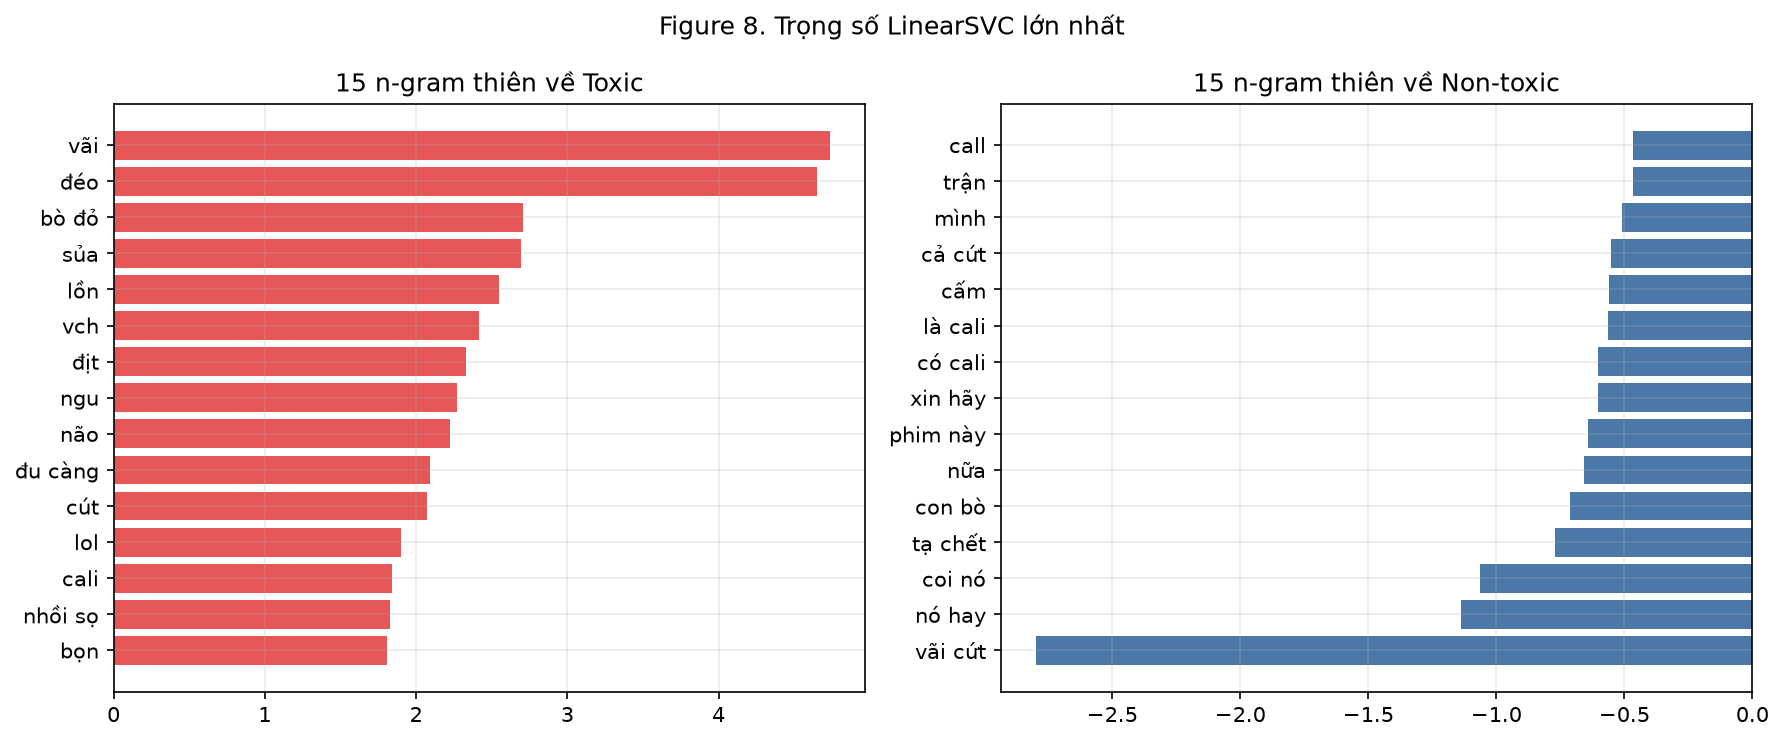

In [16]:
# Kiểm toán nhãn: toàn bộ ca lỗi + mẫu ngẫu nhiên các ca đúng (để so sánh)
rng_a = np.random.default_rng(RANDOM_STATE)
ok_pool = df_pred[df_pred.error_type == 'Correct']
ok_sample = ok_pool.loc[rng_a.choice(ok_pool.index, size=min(50, len(ok_pool)), replace=False)]
audit = pd.concat([df_err.drop(columns=['top_ngram_contributions']), ok_sample])[
    ['id_comment', 'comment', 'true_label', 'predicted_label', 'decision_score', 'error_type']].copy()
audit['human_label'] = ''   # cột để người kiểm tra điền: 0 = non-toxic, 1 = toxic
audit = audit.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)   # xáo trộn để không bị thiên lệch theo loại lỗi
audit.to_csv(RESULTS_DIR / 'label_audit_sample.csv', index=False, encoding='utf-8-sig')
print(f'Đã xuất {len(audit)} bình luận vào label_audit_sample.csv (điền cột human_label rồi tính tỷ lệ bất đồng với nhãn LLM).')

# Phân tích theo độ dài bình luận
test_len = test['comment'].astype(str).str.split().str.len().to_numpy()
df_pred['word_len'] = test_len
df_pred['len_bin'] = pd.qcut(df_pred['word_len'], 4, duplicates='drop')
len_rows = []
for b, g in df_pred.groupby('len_bin', observed=True):
    n_pos = int(g.true_label.sum())
    len_rows.append({'Số từ': str(b), 'N': len(g), 'N_Toxic': n_pos,
                     'Recall': recall_score(g.true_label, g.predicted_label, zero_division=0) if n_pos else np.nan,
                     'Precision': precision_score(g.true_label, g.predicted_label, zero_division=0) if g.predicted_label.sum() else np.nan})
df_len = pd.DataFrame(len_rows)
df_len.to_csv(RESULTS_DIR / 'error_by_length.csv', index=False)
print('\n=== HIỆU NĂNG THEO ĐỘ DÀI BÌNH LUẬN (TEST) ===')
display(df_len.round(4))

# Figure 8: trọng số đặc trưng
order = np.argsort(coef)
top_neg, top_pos = order[:15], order[::-1][:15]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(feat_names[top_pos][::-1], coef[top_pos][::-1], color='#E45756'); axes[0].set_title('15 n-gram thiên về Toxic')
axes[1].barh(feat_names[top_neg], coef[top_neg], color='#4C78A8'); axes[1].set_title('15 n-gram thiên về Non-toxic')
fig.suptitle('Figure 8. Trọng số LinearSVC lớn nhất')
savefig('fig8_feature_importance.png')

In [17]:
# Độ trễ suy luận đo thực tế (văn bản thô -> tiền xử lý -> vector hóa -> điểm -> nhãn)
sample_raw = test['comment'].astype(str).to_numpy()[:1000]
def e2e_single():
    for s in sample_raw:
        sc = final_pipe.decision_function([clean_text(s)])
        _ = int(sc[0] >= theta_star)
def e2e_batch():
    sc = final_pipe.decision_function([clean_text(s) for s in sample_raw])
    _ = (sc >= theta_star).astype(int)

def timeit(fn, repeats=3):
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

t_single, t_batch = timeit(e2e_single), timeit(e2e_batch)
n_lat = len(sample_raw)
lat = {'n': n_lat, 'single_ms_per_comment': t_single / n_lat * 1000, 'single_throughput': n_lat / t_single,
       'batch_ms_per_comment': t_batch / n_lat * 1000, 'batch_throughput': n_lat / t_batch}
print('=== ĐỘ TRỄ SUY LUẬN (trung vị của 3 lần đo) ===')
print(f"Máy: {platform.processor() or platform.machine()} | {os.cpu_count()} luồng CPU | Python {sys.version.split()[0]}")
print(f"Từng bình luận một : {lat['single_ms_per_comment']:.3f} ms/bình luận ({lat['single_throughput']:,.0f} bình luận/giây)")
print(f"Theo lô {n_lat} bình luận: {lat['batch_ms_per_comment']:.3f} ms/bình luận ({lat['batch_throughput']:,.0f} bình luận/giây)")

# Ví dụ dùng mô hình đã lưu
bundle = joblib.load(MODELS_DIR / 'best_model.joblib')
def predict_toxic(texts, bundle=bundle):
    sc = bundle['pipeline'].decision_function([clean_text(t) for t in texts])
    return (sc >= bundle['threshold']).astype(int), sc
demo_labels, demo_scores = predict_toxic(['Phim hay quá, cảm ơn đoàn làm phim', 'Phim rác rưởi vc, diễn như hạch'])
print('\nDemo dự đoán từ mô hình đã lưu:', demo_labels.tolist(), np.round(demo_scores, 3).tolist())

=== ĐỘ TRỄ SUY LUẬN (trung vị của 3 lần đo) ===
Máy: AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD | 12 luồng CPU | Python 3.12.10
Từng bình luận một : 0.654 ms/bình luận (1,528 bình luận/giây)
Theo lô 1000 bình luận: 0.112 ms/bình luận (8,942 bình luận/giây)

Demo dự đoán từ mô hình đã lưu: [0, 0] [-1.195, -0.409]


## PHẦN 11. CONCLUSION

Toàn bộ nội dung bên dưới được **sinh từ các biến kết quả** ở các phần trên; chạy lại notebook với dữ liệu hoặc seed khác thì kết luận tự cập nhật theo. Phần hạn chế mang tính định tính và không chứa con số.

In [18]:
b = df_bench.set_index(['Vectorizer', 'Algorithm'])
best_nb = df_bench[df_bench.Algorithm.isin(['MultinomialNB', 'ComplementNB'])].sort_values('Mean_PR_AUC', ascending=False).iloc[0]
top_row = df_bench.iloc[0]
if tm_nodup is not None:
    near_dup_sentence = f"loại {int((~keep).sum())} mẫu near-duplicate làm F1 thay đổi {d_f1_nodup:+.4f}."
else:
    near_dup_sentence = f"không đánh giá được vì sau khi loại near-duplicate chỉ còn {n_keep} mẫu Test ({n_keep_pos} Toxic)."
if top_row.Algorithm in ('MultinomialNB', 'ComplementNB'):
    algo_sentence = (f"cấu hình đứng đầu theo PR-AUC ở baseline là **{top_row.Vectorizer} + {top_row.Algorithm}** "
                     f"(PR-AUC {top_row.Mean_PR_AUC:.4f}), là một mô hình Naive Bayes.")
else:
    algo_sentence = (f"cấu hình đứng đầu theo PR-AUC ở baseline là **{top_row.Vectorizer} + {top_row.Algorithm}** "
                     f"(PR-AUC {top_row.Mean_PR_AUC:.4f}); Naive Bayes tốt nhất là **{best_nb.Vectorizer} + {best_nb.Algorithm}** "
                     f"với PR-AUC {best_nb.Mean_PR_AUC:.4f}.")
def sig(p): return 'có ý nghĩa thống kê (p < 0,05)' if p < 0.05 else 'chưa đạt ý nghĩa thống kê (p ≥ 0,05)'

d_f1, p_f1 = full_vs_raw['toxic_f1'][0], full_vs_raw['toxic_f1'][2]
d_rec, p_rec = full_vs_raw['toxic_recall'][0], full_vs_raw['toxic_recall'][2]
d_pre, p_pre = full_vs_raw['toxic_precision'][0], full_vs_raw['toxic_precision'][2]
d_pr, p_pr = bow_vs_tfidf['pr_auc']
d_f1_bt, p_f1_bt = bow_vs_tfidf['toxic_f1']

summary_md = f"""
### 1. Mô hình được chọn
**LinearSVC (C = {best_spec['C']}, class_weight = {best_spec['class_weight']}) + TF-IDF n-gram {best_spec['ngram']}**, ngưỡng quyết định **θ\\* = {theta_star:.4f}** (dò trên OOF của Dev, chọn theo PR-AUC trung bình qua 5-fold CV).

### 2. Kết quả trên Test khóa (N = {n_test_total:,}; Toxic = {n_test_pos})

| Chỉ số | Giá trị | CI 95% | Phương pháp CI |
| :--- | :---: | :---: | :---: |
""" + '\n'.join(
    f"| {r.Metric} | {r.Value:.4f} | " + (f"[{r.CI95_low:.4f}, {r.CI95_high:.4f}]" if not np.isnan(r.CI95_low) else '—') + f" | {r.CI_method or '—'} |"
    for r in df_report.itertuples()) + f"""

Confusion matrix: TP = {tm['tp']}, FP = {tm['fp']}, FN = {tm['fn']}, TN = {tm['tn']}.
Vì chỉ có {n_test_pos} mẫu Toxic trong Test, các khoảng tin cậy khá rộng (CI của Recall rộng {(ci_rec[1] - ci_rec[0]) * 100:.1f} điểm phần trăm); các chênh lệch nhỏ hơn mức này không nên được diễn giải là khác biệt thật.

### 3. Các phát hiện chính (đều tính từ CV trên Dev)
* **Tiền xử lý:** so với văn bản gốc, tiền xử lý đầy đủ thay đổi Toxic F1 **{d_f1 * 100:+.2f} điểm** ({sig(p_f1)}), Recall **{d_rec * 100:+.2f} điểm** ({sig(p_rec)}), Precision **{d_pre * 100:+.2f} điểm** ({sig(p_pre)}).
* **BoW so với TF-IDF** (cùng siêu tham số, 15 lượt CV): PR-AUC chênh **{d_pr:+.4f}** ({sig(p_pr)}); Toxic F1 ở ngưỡng mặc định chênh **{d_f1_bt:+.4f}** ({sig(p_f1_bt)}).
* **Thuật toán:** {algo_sentence}
* **Dò ngưỡng:** trên OOF, dịch ngưỡng từ 0 sang {theta_star:.4f} làm Recall {oof_default['recall']:.4f} → {oof_opt['recall']:.4f}, Precision {oof_default['precision']:.4f} → {oof_opt['precision']:.4f}, F1 {oof_default['f1']:.4f} → {oof_opt['f1']:.4f}. Trên Test, F1 là {tm_default['f1']:.4f} ở ngưỡng mặc định và {tm['f1']:.4f} ở θ\\*.
* **Độ ổn định:** Toxic F1 qua 15 lượt CV là {folds_best['toxic_f1'].mean():.4f} ± {folds_best['toxic_f1'].std(ddof=1):.4f} (ngưỡng mặc định).
* **Độ nhạy với near-duplicate:** {near_dup_sentence}
* **Suy luận:** {lat['batch_ms_per_comment']:.3f} ms/bình luận khi xử lý theo lô, {lat['single_ms_per_comment']:.3f} ms/bình luận khi xử lý từng cái ({platform.processor() or platform.machine()}, {os.cpu_count()} luồng).

### 4. Hạn chế
1. **Nhãn do LLM gán, chưa được kiểm định bởi người.** Một phần ca "lỗi mô hình" có thể là lỗi nhãn; cần điền `label_audit_sample.csv` và báo cáo tỷ lệ bất đồng trước khi kết luận về chất lượng thật của mô hình.
2. **Số mẫu Toxic trong Test ít**, nên mọi chỉ số của lớp Toxic có sai số lấy mẫu đáng kể (xem CI).
3. **Một chủ đề, một nền tảng, một khoảng thời gian** (bình luận về một bộ phim trên Facebook). Chưa có bằng chứng về khả năng tổng quát hóa sang chủ đề khác.
4. **Mô hình n-gram không hiểu ngữ cảnh**: mỉa mai, ẩn ý và chuỗi trả lời (thread) không được xử lý.
5. **Từ điển teencode là lựa chọn thủ công**: các ánh xạ như `cc`, `vc` có thể sinh báo động giả khi người dùng dùng với nghĩa khác (ví dụ `cc` = "các cậu").
6. **Chưa có nhóm theo bài đăng/người dùng** trong dữ liệu nên việc chia ngẫu nhiên không loại trừ được phụ thuộc theo bài đăng hoặc theo tác giả.

### 5. Hướng phát triển
Kiểm định nhãn bởi người và đo độ đồng thuận (Cohen's κ); gắn nhóm theo bài đăng để chia `GroupKFold`; thử mô hình tiền huấn luyện tiếng Việt (PhoBERT, ViSoBERT) và so sánh với baseline này trên **cùng** Test khóa.
"""
display(Markdown(summary_md))
(RESULTS_DIR / 'conclusion.md').write_text(summary_md, encoding='utf-8')


### 1. Mô hình được chọn
**LinearSVC (C = 1.0, class_weight = None) + TF-IDF n-gram (1, 2)**, ngưỡng quyết định **θ\* = -0.4049** (dò trên OOF của Dev, chọn theo PR-AUC trung bình qua 5-fold CV).

### 2. Kết quả trên Test khóa (N = 4,851; Toxic = 128)

| Chỉ số | Giá trị | CI 95% | Phương pháp CI |
| :--- | :---: | :---: | :---: |
| Accuracy | 0.9878 | [0.9843, 0.9906] | Wilson |
| Toxic Precision | 0.7760 | [0.6953, 0.8402] | Wilson |
| Toxic Recall | 0.7578 | [0.6768, 0.8238] | Wilson |
| Toxic F1 | 0.7668 | [0.7027, 0.8252] | Bootstrap (1000) |
| Macro F1 | 0.8803 | [0.8473, 0.9099] | Bootstrap (1000) |
| PR-AUC | 0.8405 | [0.7813, 0.8952] | Bootstrap (1000) |
| Weighted F1 | 0.9878 | — | — |
| ROC-AUC | 0.9832 | — | — |
| Balanced Accuracy | 0.8759 | — | — |
| MCC | 0.7606 | — | — |

Confusion matrix: TP = 97, FP = 28, FN = 31, TN = 4695.
Vì chỉ có 128 mẫu Toxic trong Test, các khoảng tin cậy khá rộng (CI của Recall rộng 14.7 điểm phần trăm); các chênh lệch nhỏ hơn mức này không nên được diễn giải là khác biệt thật.

### 3. Các phát hiện chính (đều tính từ CV trên Dev)
* **Tiền xử lý:** so với văn bản gốc, tiền xử lý đầy đủ thay đổi Toxic F1 **+1.96 điểm** (có ý nghĩa thống kê (p < 0,05)), Recall **+3.20 điểm** (có ý nghĩa thống kê (p < 0,05)), Precision **+0.10 điểm** (chưa đạt ý nghĩa thống kê (p ≥ 0,05)).
* **BoW so với TF-IDF** (cùng siêu tham số, 15 lượt CV): PR-AUC chênh **+0.0751** (có ý nghĩa thống kê (p < 0,05)); Toxic F1 ở ngưỡng mặc định chênh **-0.0730** (có ý nghĩa thống kê (p < 0,05)).
* **Thuật toán:** cấu hình đứng đầu theo PR-AUC ở baseline là **TF-IDF + LinearSVC** (PR-AUC 0.7967); Naive Bayes tốt nhất là **BoW + MultinomialNB** với PR-AUC 0.3362.
* **Dò ngưỡng:** trên OOF, dịch ngưỡng từ 0 sang -0.4049 làm Recall 0.4882 → 0.7523, Precision 0.9337 → 0.7543, F1 0.6412 → 0.7533. Trên Test, F1 là 0.6492 ở ngưỡng mặc định và 0.7668 ở θ\*.
* **Độ ổn định:** Toxic F1 qua 15 lượt CV là 0.6402 ± 0.0376 (ngưỡng mặc định).
* **Độ nhạy với near-duplicate:** loại 339 mẫu near-duplicate làm F1 thay đổi -0.0057.
* **Suy luận:** 0.112 ms/bình luận khi xử lý theo lô, 0.654 ms/bình luận khi xử lý từng cái (AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD, 12 luồng).

### 4. Hạn chế
1. **Nhãn do LLM gán, chưa được kiểm định bởi người.** Một phần ca "lỗi mô hình" có thể là lỗi nhãn; cần điền `label_audit_sample.csv` và báo cáo tỷ lệ bất đồng trước khi kết luận về chất lượng thật của mô hình.
2. **Số mẫu Toxic trong Test ít**, nên mọi chỉ số của lớp Toxic có sai số lấy mẫu đáng kể (xem CI).
3. **Một chủ đề, một nền tảng, một khoảng thời gian** (bình luận về một bộ phim trên Facebook). Chưa có bằng chứng về khả năng tổng quát hóa sang chủ đề khác.
4. **Mô hình n-gram không hiểu ngữ cảnh**: mỉa mai, ẩn ý và chuỗi trả lời (thread) không được xử lý.
5. **Từ điển teencode là lựa chọn thủ công**: các ánh xạ như `cc`, `vc` có thể sinh báo động giả khi người dùng dùng với nghĩa khác (ví dụ `cc` = "các cậu").
6. **Chưa có nhóm theo bài đăng/người dùng** trong dữ liệu nên việc chia ngẫu nhiên không loại trừ được phụ thuộc theo bài đăng hoặc theo tác giả.

### 5. Hướng phát triển
Kiểm định nhãn bởi người và đo độ đồng thuận (Cohen's κ); gắn nhóm theo bài đăng để chia `GroupKFold`; thử mô hình tiền huấn luyện tiếng Việt (PhoBERT, ViSoBERT) và so sánh với baseline này trên **cùng** Test khóa.


3345

In [19]:
# Lưu tóm tắt thực nghiệm và môi trường để tái lập
experiment_summary = {
    'data_path': str(DATA_PATH), 'n_raw': int(n_rows0), 'n_after_cleaning': int(len(df)),
    'n_dev': int(len(dev)), 'n_test': int(len(test)), 'n_test_toxic': n_test_pos,
    'random_state': RANDOM_STATE, 'cv': {'n_splits': N_SPLITS, 'n_repeats': N_REPEATS},
    'best_config': best_config, 'test_metrics': {k: (float(v) if not isinstance(v, int) else v) for k, v in tm.items()},
    'test_ci95': {'accuracy': ci_acc, 'precision': ci_prec, 'recall': ci_rec, **{k: list(v) for k, v in ci_boot.items()}},
    'latency': lat,
    'versions': {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
                 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__, 'joblib': joblib.__version__},
}
(RESULTS_DIR / 'experiment_summary.json').write_text(json.dumps(experiment_summary, indent=2, ensure_ascii=False, default=float), encoding='utf-8')
(RESULTS_DIR / 'requirements_used.txt').write_text('\n'.join(
    f'{k}=={v}' for k, v in experiment_summary['versions'].items() if k != 'python') + '\n', encoding='utf-8')
print('Đã lưu experiment_summary.json và requirements_used.txt vào', RESULTS_DIR)
print('Các file đầu ra:', sorted(p.name for p in RESULTS_DIR.iterdir()))

Đã lưu experiment_summary.json và requirements_used.txt vào D:\file moi btl;\BENCHMARK_TOXIC\results
Các file đầu ra: ['ablation_summary.csv', 'benchmark_summary.csv', 'best_configuration.json', 'bow_vs_tfidf.csv', 'conclusion.md', 'error_analysis.csv', 'error_by_length.csv', 'experiment_summary.json', 'hyperparameter_results.csv', 'label_audit_sample.csv', 'requirements_used.txt', 'stability_summary.csv', 'test_classification_report.csv', 'test_metrics.csv', 'test_predictions.csv']
